# 1 Load the dataset

## 1.1 Download dataset

In [1]:
!mkdir -p ~/.kaggle
!echo "{\"username\":\"arashxy\",\"key\":\"84fa1ea1efbd77ca2814f144bf9c810e\"}" | cat > ~/.kaggle/kaggle.json

In [2]:
!kaggle datasets download -d emineyetm/fake-news-detection-datasets

 98% 40.0M/41.0M [00:01<00:00, 28.0MB/s]
100% 41.0M/41.0M [00:01<00:00, 24.6MB/s]


In [3]:
!unzip -x fake-news-detection-datasets.zip

Archive:  fake-news-detection-datasets.zip
  inflating: News _dataset/Fake.csv  
  inflating: News _dataset/True.csv  


## 1.2 Import it with pandas

In [4]:
import pandas as pd
import numpy as np

In [5]:
fake = pd.read_csv("News _dataset/Fake.csv")
true = pd.read_csv("News _dataset/True.csv")

In [6]:
fake

,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"
...,...,...,...,...
23476,McPain: John McCain Furious That Iran Treated ...,21st Century Wire says As 21WIRE reported earl...,Middle-east,"January 16, 2016"
23477,JUSTICE? Yahoo Settles E-mail Privacy Class-ac...,21st Century Wire says It s a familiar theme. ...,Middle-east,"January 16, 2016"
23478,Sunnistan: US and Allied ‘Safe Zone’ Plan to T...,Patrick Henningsen 21st Century WireRemember ...,Middle-east,"January 15, 2016"
23479,How to Blow $700 Million: Al Jazeera America F...,21st Century Wire says Al Jazeera America will...,Middle-east,"January 14, 2016"


In [7]:
true

,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"
...,...,...,...,...
21412,'Fully committed' NATO backs new U.S. approach...,BRUSSELS (Reuters) - NATO allies on Tuesday we...,worldnews,"August 22, 2017"
21413,LexisNexis withdrew two products from Chinese ...,"LONDON (Reuters) - LexisNexis, a provider of l...",worldnews,"August 22, 2017"
21414,Minsk cultural hub becomes haven from authorities,MINSK (Reuters) - In the shadow of disused Sov...,worldnews,"August 22, 2017"
21415,Vatican upbeat on possibility of Pope Francis ...,MOSCOW (Reuters) - Vatican Secretary of State ...,worldnews,"August 22, 2017"


# 2 Data Analysis

## 2.1 Length of the datasets

In [8]:
len(fake)

23481

In [9]:
len(true)

21417

## 2.2 Finding null values

In [8]:
fake.isnull().sum()

title      0
text       0
subject    0
date       0
dtype: int64

In [11]:
true.isnull().sum()

title      0
text       0
subject    0
date       0
dtype: int64

## 2.3 Min/Max length of news titles

In [12]:
title_min_length_fake = fake['title'].str.len().min()
title_max_length_fake = fake['title'].str.len().max()
print(title_min_length_fake, title_max_length_fake)

8 286


In [13]:
title_min_length_true = true['title'].str.len().min()
title_max_length_true = true['title'].str.len().max()
print(title_min_length_true, title_max_length_true)

26 133


## 2.4 Min/Max length of newes texts

In [14]:
text_min_length_fake = fake['text'].str.len().min()
text_max_length_fake = fake['text'].str.len().max()
print(text_min_length_fake, text_max_length_fake)

1 51794


In [15]:
text_min_length_true = true['text'].str.len().min()
text_max_length_true = true['text'].str.len().max()
print(text_min_length_true, text_max_length_true)

1 29781


## 2.5 Unique subjects

In [16]:
fake_subjects = fake['subject'].unique()
fake_subjects

array(['News', 'politics', 'Government News', 'left-news', 'US_News',
       'Middle-east'], dtype=object)

In [17]:
true_subjects = true['subject'].unique()
true_subjects

array(['politicsNews', 'worldnews'], dtype=object)

# 3 Preprocessing

## 3.1 Add label 0 for fake news and 1 for true news

In [9]:
fake['label'] = 0
true['label'] = 1

In [19]:
fake

,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",0
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",0
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",0
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",0
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",0
...,...,...,...,...,...
23476,McPain: John McCain Furious That Iran Treated ...,21st Century Wire says As 21WIRE reported earl...,Middle-east,"January 16, 2016",0
23477,JUSTICE? Yahoo Settles E-mail Privacy Class-ac...,21st Century Wire says It s a familiar theme. ...,Middle-east,"January 16, 2016",0
23478,Sunnistan: US and Allied ‘Safe Zone’ Plan to T...,Patrick Henningsen 21st Century WireRemember ...,Middle-east,"January 15, 2016",0
23479,How to Blow $700 Million: Al Jazeera America F...,21st Century Wire says Al Jazeera America will...,Middle-east,"January 14, 2016",0


In [20]:
true

,title,text,subject,date,label
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017",1
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017",1
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017",1
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017",1
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017",1
...,...,...,...,...,...
21412,'Fully committed' NATO backs new U.S. approach...,BRUSSELS (Reuters) - NATO allies on Tuesday we...,worldnews,"August 22, 2017",1
21413,LexisNexis withdrew two products from Chinese ...,"LONDON (Reuters) - LexisNexis, a provider of l...",worldnews,"August 22, 2017",1
21414,Minsk cultural hub becomes haven from authorities,MINSK (Reuters) - In the shadow of disused Sov...,worldnews,"August 22, 2017",1
21415,Vatican upbeat on possibility of Pope Francis ...,MOSCOW (Reuters) - Vatican Secretary of State ...,worldnews,"August 22, 2017",1


## 3.2 Combine fake and true dataset and mixing then randomly

In [10]:
all_data = pd.concat([fake, true])
random_permutation = np.random.permutation(len(all_data))
all_data = all_data.iloc[random_permutation]

In [11]:
all_data

,title,text,subject,date,label
12313,JIMMY KIMMEL: A Politically Correct Thanksgivi...,,politics,"Nov 23, 2016",0
1789,State Department OKs possible sale to Canada o...,WASHINGTON (Reuters) - The U.S. State Departme...,politicsNews,"September 12, 2017",1
12888,HILLARY Calls On CRANKY SOCIALIST She Stole El...,Poor Bernie. He s been a public servant his wh...,politics,"Sep 29, 2016",0
8180,Anti-Gay Texas Attorney General Faces Disbarment,The Texas Bar Association is stepping up to th...,News,"February 11, 2016",0
14350,"Bernie Sanders: When you’re White, you don’t k...",Bernie Sanders is so focused on pandering to b...,politics,"Mar 7, 2016",0
...,...,...,...,...,...
9115,Sales to people on terrorism watch lists shoul...,WASHINGTON (Reuters) - The National Rifle Asso...,politicsNews,"June 15, 2016",1
10349,JUDGE NAPOLITANO AGREES WITH TRUMP: AG Session...,Judge Andrew Napolitano reacted to an intervie...,politics,"Jul 20, 2017",0
17339,Iraqi forces remove Kurdish flag from Kirkuk g...,BAGHDAD (Reuters) - Iraqi forces removed on Mo...,worldnews,"October 16, 2017",1
14433,Mugabe holds more exit talks with generals: st...,HARARE (Reuters) - Zimbabwe President Robert M...,worldnews,"November 19, 2017",1


<Axes: xlabel='label', ylabel='count'>

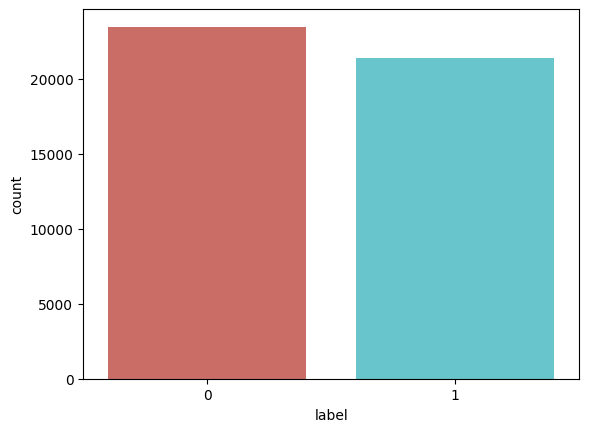

In [12]:
import seaborn as sb

def create_distribution(dataFile):
    return sb.countplot(x='label', data=dataFile, palette='hls')

create_distribution(all_data)

## 3.3 Combining the training features

In [13]:
all_data['training_feature'] = all_data['title'] + ' ' + all_data['text'] + ' ' + all_data['subject']

In [14]:
df = all_data

# 4 Training Classifier

## 4.1 Extracting the data

In [15]:
X = all_data['training_feature'].values
y = all_data['label'].values

In [16]:
X.shape, y.shape

((44898,), (44898,))

## 4.2 Encoding the input with TFIDF

In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [18]:
vectorizer = TfidfVectorizer()

In [19]:
X_encode = vectorizer.fit_transform(X)

## 4.3 Separating 20% for test

In [20]:
from sklearn.model_selection import train_test_split

In [21]:
X_train, X_test, y_train, y_test = train_test_split(X_encode, y, test_size = 0.2, stratify=y)

## 4.4 Trying logistic regression

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [23]:
model = LogisticRegression()
model.fit(X_train,y_train)

LogisticRegression()

In [24]:
# Model accuracy on the test set
test_y_hat = model.predict(X_test)
print("Test Accuracy:", accuracy_score(test_y_hat, y_test))

# Model Accuracy on  training set
train_y_hat = model.predict(X_train)
print("Train Accuracy:", accuracy_score(train_y_hat,y_train))

Test Accuracy: 0.9923162583518931
Train Accuracy: 0.9948493791413776


In [25]:
from sklearn.metrics import precision_score, recall_score, f1_score

In [26]:
print ("Test Precision:", precision_score(y_test, test_y_hat,))
print ("Test Recall:", recall_score(y_test, test_y_hat,))
print("Test F1:", f1_score(y_test, test_y_hat,))

Test Precision: 0.9909154437456325
Test Recall: 0.9929971988795518
Test F1: 0.9919552291010842


In [27]:
print ("Train Precision:", precision_score(y_train, train_y_hat,))
print ("Train Recall:", recall_score(y_train, train_y_hat,))
print("Train F1:", f1_score(y_train, train_y_hat,))

Train Precision: 0.9942260585559314
Train Recall: 0.9949804470904103
Train F1: 0.9946031097756645


In [28]:
import itertools
from matplotlib import pyplot as plt
from sklearn.metrics import confusion_matrix

def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, cm[i, j],
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

Confusion matrix, without normalization


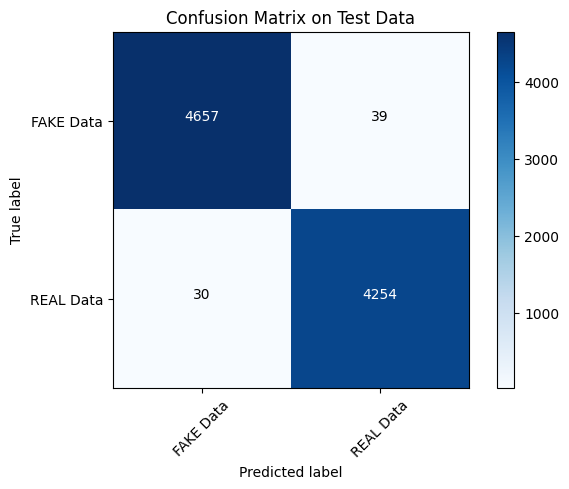

In [29]:
cm = confusion_matrix(y_test, test_y_hat)
plot_confusion_matrix(cm, classes=['FAKE Data', 'REAL Data'], title="Confusion Matrix on Test Data")

Confusion matrix, without normalization


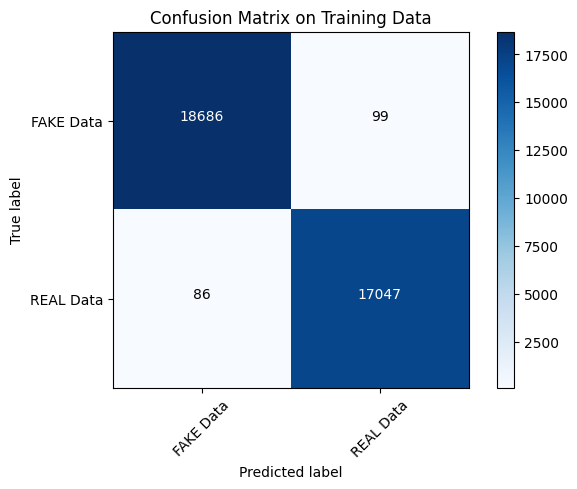

In [30]:
cm = confusion_matrix(y_train, train_y_hat)
plot_confusion_matrix(cm, classes=['FAKE Data', 'REAL Data'], title="Confusion Matrix on Training Data")

# 5 Finding Patterns in fake and true news

## 5.1 True and Fake news encoding visualization in 2d

In [31]:
from sklearn.decomposition import TruncatedSVD

In [32]:
svd = TruncatedSVD(n_components=2)
X_reduced = svd.fit_transform(X_encode)

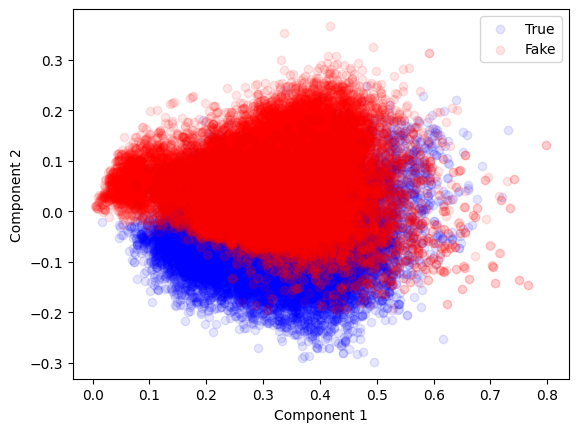

In [33]:
plt.scatter(X_reduced[y == 1, 0], X_reduced[y == 1, 1], color='blue', label='True', alpha=0.1)
plt.scatter(X_reduced[y == 0, 0], X_reduced[y == 0, 1], color='red', label='Fake', alpha=0.1)

plt.xlabel('Component 1')
plt.ylabel('Component 2')
plt.legend()
plt.show()

## 5.2 Fake news relationship visualization

In [34]:
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [35]:
scaler = StandardScaler(with_mean=False)
tfidf_data_scaled = scaler.fit_transform(X_encode[y==0])

In [36]:
n_clusters = 5
kmeans = KMeans(n_clusters=n_clusters, random_state=42)
labels = kmeans.fit_predict(tfidf_data_scaled)

/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


In [40]:
n_components_svd = 2
svd = TruncatedSVD(n_components=n_components_svd, random_state=42)
tfidf_data_svd = svd.fit_transform(tfidf_data_scaled)

In [38]:
tsne = TSNE(n_components=2, random_state=42)
tfidf_data_tsne = tsne.fit_transform(tfidf_data_svd)

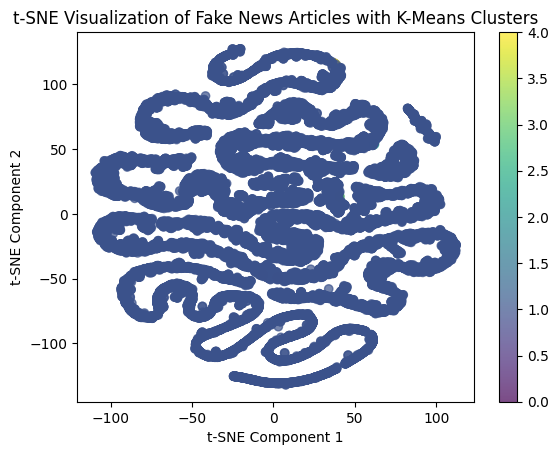

In [39]:
plt.scatter(tfidf_data_tsne[:, 0], tfidf_data_tsne[:, 1], c=labels, cmap='viridis', alpha=0.7)
plt.title('t-SNE Visualization of Fake News Articles with K-Means Clusters')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.colorbar()
plt.show()

In [41]:
all_data.reset_index(drop= True,inplace=True)

In [42]:
label_train = all_data.label

In [43]:
all_data = all_data.drop("label", axis = 1)

In [38]:
all_data['text'][2188]

'LIMA (Reuters) - Six farmers were shot dead in the Peruvian Amazon by a group of masked men in an apparent dispute over land rights, a police officer and a tribal leader said on Thursday. Five bodies, one with hands and feet bound, had been thrown in a river and a sixth was found by the side of an unpaved road in the jungle region Ucayali, police officer Raul Huari said. The victims were part of a community of peasant farmers that had refused to leave the lands they work on when pressured by oil palm growers, said Robert Guimaraes, the head of an indigenous federation in Ucayali. Witnesses testified that a group of between 30 and 40 men carrying shotguns tried to kill some 20 farmers altogether, Huari said.  They said they showed up, surrounded them and just started shooting. Fortunately, some managed to escape,  he said.  In my 24 years of working I ve never seen anything like this.  Huari said the murders appeared to be linked to a land dispute, and a special police unit and prosecu

In [44]:
import nltk
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [45]:
import pandas as pd
import sklearn
import itertools
import numpy as np
import seaborn as sb
import re
import nltk
import pickle
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn import metrics
from sklearn.metrics import confusion_matrix
from matplotlib import pyplot as plt
from sklearn.linear_model import PassiveAggressiveClassifier
from nltk.stem import WordNetLemmatizer
from nltk.corpus import stopwords

In [46]:
lemmatizer = WordNetLemmatizer()
stpwrds = list(stopwords.words('english'))

In [47]:
import nltk
nltk.download('punkt')
nltk.download('wordnet')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


True

In [48]:
for x in range(len(all_data)) :
    corpus = []
    review = all_data['text'][x]
    review = re.sub(r'[^a-zA-Z\s]', '', review)
    review = review.lower()
    review = nltk.word_tokenize(review)
    for y in review :
        if y not in stpwrds :
            corpus.append(lemmatizer.lemmatize(y))
    review = ' '.join(corpus)
    all_data['text'][x] = review

In [49]:
X_train, X_test, Y_train, Y_test = train_test_split(all_data['text'], label_train, test_size=0.2, random_state=1)


In [50]:
tfidf_v = TfidfVectorizer()
tfidf_X_train = tfidf_v.fit_transform(X_train)
tfidf_X_test = tfidf_v.transform(X_test)

In [51]:
def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, cm[i, j],
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

In [52]:
classifier = PassiveAggressiveClassifier()
classifier.fit(tfidf_X_train,Y_train)

PassiveAggressiveClassifier()

Accuracy: 99.57%
Confusion matrix, without normalization


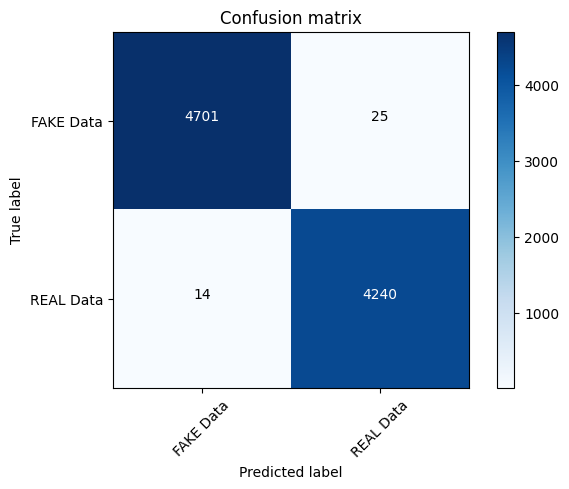

In [53]:
Y_pred = classifier.predict(tfidf_X_test)
score = metrics.accuracy_score(Y_test, Y_pred)
print(f'Accuracy: {round(score*100,2)}%')
cm = metrics.confusion_matrix(Y_test, Y_pred)
plot_confusion_matrix(cm, classes=['FAKE Data', 'REAL Data'])

In [54]:
pickle.dump(classifier,open('./model.pkl', 'wb'))

In [55]:
# load the model from disk
loaded_model = pickle.load(open('./model.pkl', 'rb'))

In [56]:
def fake_news_det(news):
    review = news
    review = re.sub(r'[^a-zA-Z\s]', '', review)
    review = review.lower()
    review = nltk.word_tokenize(review)
    for y in review :
        if y not in stpwrds :
            corpus.append(lemmatizer.lemmatize(y))
    input_data = [' '.join(corpus)]
    vectorized_input_data = tfidf_v.transform(input_data)
    prediction = loaded_model.predict(vectorized_input_data)
    if prediction[0] == 0:
        print("Prediction of the News :  Looking Fake⚠ News📰 ")
    else:
        print("Prediction of the News : Looking Real News📰 ")

In [58]:
fake_news_det("news is very good")

Prediction of the News :  Looking Fake⚠ News📰 


In [57]:
df.label.value_counts()

0    23481
1    21417
Name: label, dtype: int64

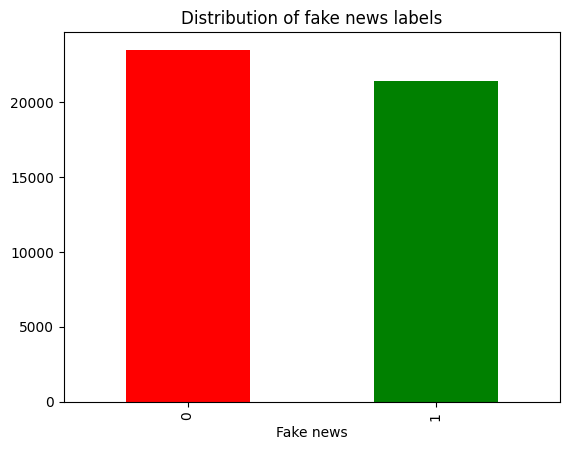

In [59]:
df.label.value_counts().plot(kind = 'bar', color = ['red','green'])
plt.xlabel("Fake news")
plt.title("Distribution of fake news labels")
plt.show()

In [60]:
df.isnull().sum()

title               0
text                0
subject             0
date                0
label               0
training_feature    0
dtype: int64

##CLEANING: Lowercasing + remove stop words + remove punctuation


In [61]:
df['Full_text'] = df['title'] + df['text']


In [62]:
import spacy
from spacy.lang.en import English
from nltk.corpus import stopwords
import nltk
import time

## download the dictionary for stopwords
nltk.download('stopwords')

## get the set of stopwords
stop_words_set = set(stopwords.words('english'))

## Load English tokenizer from spacy
nlp = English()
tokenizer = nlp.tokenizer ## make instance

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [63]:
## Create function to clean text -- lowercase, remove non alphanumeric, remove stop words
def optimized_preprocess(texts): ## Takes in a list of texts, i.e. the entire corpus
    result = []

    # Tokenize using spaCy's tokenizer
    for text in texts:
        tokens = [token.text.lower() for token in tokenizer(text) if token.text.isalpha() and token.text.lower() not in stop_words_set]
        result.append(" ".join(tokens))

    return result

# Process data
s = time.time()
preprocessed_texts = optimized_preprocess(df.Full_text)
print('Time to clean ', time.time() - s)

Time to clean  95.9755470752716


In [64]:
df['Full_text_cleaned'] = preprocessed_texts

In [65]:
## Check cleaned text
print(df.Full_text_cleaned.head())

## Read some in full
print(df.Full_text_cleaned[10][0:1000])

0    jimmy kimmel politically correct thanksgiving ...
1    state department oks possible sale canada bill...
2    hillary calls cranky socialist stole election ...
3    anti gay texas attorney general faces disbarme...
4    bernie sanders white know like poor live ghett...
Name: Full_text_cleaned, dtype: object
wrong transgender bathrooms guy awesome man seattle wandered women locker room full little girls liberal seattle gets votes outrage transgender man hangs women locker room see seattle passed gender neutral law said feel like woman use women bathroom locker room great example pass good idea clayton cramer asks problem transgender restrooms answers question links news go source original story clicking word links cross dressing man allegedly videotaped women restroom police sex offender posed woman went women locker room police man bra wig found women bathroom admitted offense showered girls locker room sexual gratification cross dressing peeper infiltrates cal women locker room m

In [66]:
from collections import Counter ## for counting words

## Get real and fake subsets
fake_text = df[df.label == 1]["Full_text_cleaned"]
real_text = df[df.label == 0]["Full_text_cleaned"]

In [67]:
## Entire vocabulary
vocab_set = set((" ".join(df.Full_text_cleaned)).split())
non_unique_set = (" ".join(df.Full_text_cleaned)).split()

In [69]:
## Get sizes of vocab, entire corpus, ratio
print('Vocab size : ', len(vocab_set))
print('Entire word count : ', len(non_unique_set))
print('Ratio of word count to vocab size : ', len(non_unique_set)/len(vocab_set) )

Vocab size :  114798
Entire word count :  10627734
Ratio of word count to vocab size :  92.5776929911671


In [70]:
## Check
print(fake_text.head())
print(real_text.head())

1     state department oks possible sale canada bill...
5     trump tests dealmaker image sell healthcare bi...
8     saudi arabia hopes recognize jerusalem capital...
9     two trump campaign officials met russian envoy...
12    trump host thai prime minister october white h...
Name: Full_text_cleaned, dtype: object
0    jimmy kimmel politically correct thanksgiving ...
2    hillary calls cranky socialist stole election ...
3    anti gay texas attorney general faces disbarme...
4    bernie sanders white know like poor live ghett...
6    trump accused media committing treason saying ...
Name: Full_text_cleaned, dtype: object


In [71]:
## COUNT THE WORDS

## First, turn a list of lists into just one list -- i.e. join all documents together into
## one giant document/ string
fake_text_giant_string = " ".join(fake_text)
print(len(fake_text_giant_string))
real_text_giant_string = " ".join(real_text)
print(len(real_text_giant_string))


## Now, update to the Counter object to begin counting
## Rmb to split to only feed words
fake_words_counter = Counter(fake_text_giant_string.split())
real_words_counter = Counter(real_text_giant_string.split())

37646245
41289012


In [72]:
## See results
print(type(fake_words_counter))
print(fake_words_counter.most_common(10)) ## Most common words for fake news
print(real_words_counter.most_common(10)) ## Most common words for real news

<class 'collections.Counter'>
[('said', 99073), ('trump', 60008), ('would', 32018), ('president', 28607), ('reuters', 27610), ('state', 21615), ('government', 19187), ('house', 17793), ('new', 16954), ('republican', 16872)]
[('trump', 87602), ('said', 33925), ('president', 28293), ('people', 26970), ('one', 24905), ('would', 23865), ('obama', 21085), ('clinton', 20160), ('like', 18429), ('donald', 17307)]


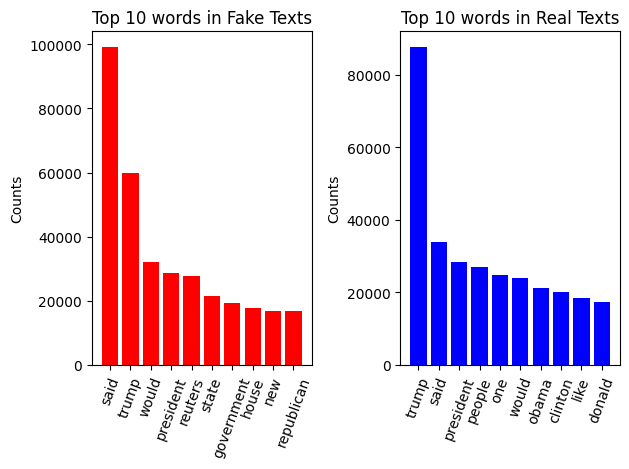

In [73]:
## Visualise the top words

fake_top_10 = fake_words_counter.most_common(10)
x,y = zip(*fake_top_10)

true_top_10 = real_words_counter.most_common(10)
x2,y2 = zip(*true_top_10)

## Plot
# Plotting fake data
plt.subplot(1, 2, 1)  # (nrows, ncols, index)
plt.bar(x, y, color='red')
plt.title('Top 10 words in Fake Texts')
plt.xticks(rotation=70)
plt.ylabel('Counts')

# Plotting real data
plt.subplot(1, 2, 2)
plt.bar(x2, y2, color='blue')
plt.title('Top 10 words in Real Texts')
plt.xticks(rotation=70)
plt.ylabel('Counts')

plt.tight_layout()
plt.show()

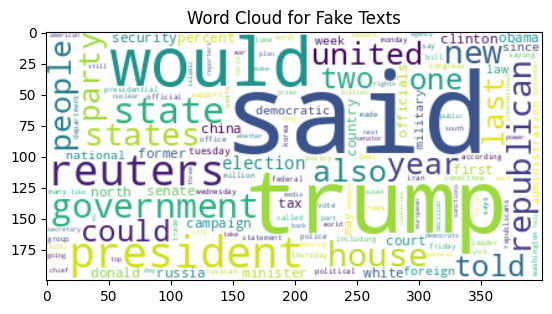

In [74]:
from wordcloud import WordCloud

fake_WC = WordCloud(background_color = 'white').generate_from_frequencies(fake_words_counter)

plt.imshow(fake_WC, interpolation = 'bilinear')
plt.title('Word Cloud for Fake Texts')
plt.show()

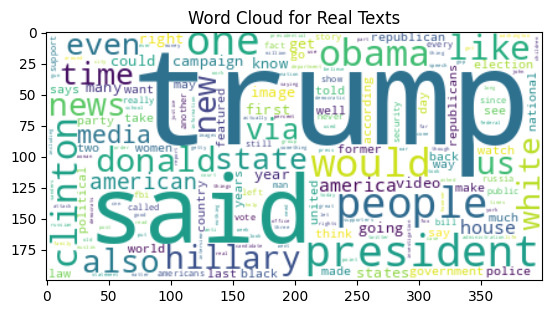

In [75]:
real_WC = WordCloud(background_color = 'white').generate_from_frequencies(real_words_counter)

plt.imshow(real_WC, interpolation = 'bilinear')
plt.title('Word Cloud for Real Texts')
plt.show()

In [76]:
fake_lengths = fake_text.str.split().apply(len)
print(fake_lengths)

real_lengths = real_text.str.split().apply(len)
print(real_lengths)

1         58
5        655
8        162
9         73
12        28
        ... 
44891    174
44892    119
44893     54
44895     74
44896     52
Name: Full_text_cleaned, Length: 21417, dtype: int64
0          7
2        258
3        219
4        130
6        308
        ... 
44887    238
44889    201
44890    219
44894    139
44897     25
Name: Full_text_cleaned, Length: 23481, dtype: int64


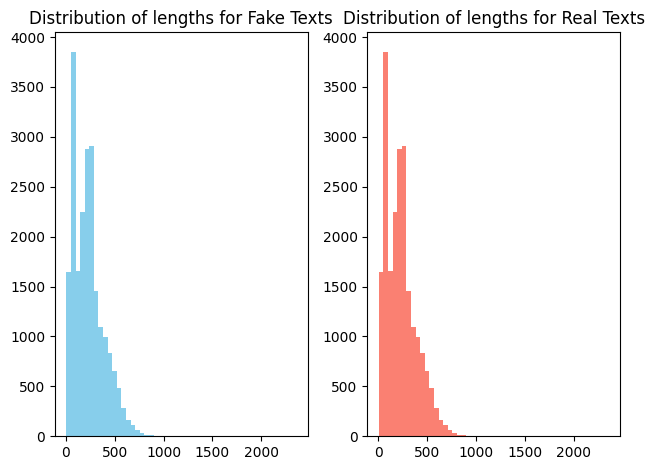

In [77]:
## Fake one
plt.subplot(1,2,1)
plt.hist(fake_lengths, bins = 50, color = 'skyblue')
plt.title('Distribution of lengths for Fake Texts')

## Real one
plt.subplot(1,2,2)
plt.hist(fake_lengths, bins = 50, color = 'salmon')
plt.title('Distribution of lengths for Real Texts')

##
plt.tight_layout()
plt.show()

##Feature engineering: Bags of Words model


NLP models cannot take in raw text, as machine learning models only understand numbers and vectors. To feed our real and fake news data into a model, we must first convert the text into something vectorial, and one option is the BOW model.

The BoW model treats text as an unordered set of words, where the sequence doesn't matter. We can already see how this is an obvious limitation, but this can be the first way forward.

The first thing BoW does it to create a vocabulary of all the words. This will essentially become our predictors, i.e. each word is a predictor or a feature (e.g. such as how education, age, industry are predictors for wage prediction). In this case, each document is a sample, as will be represented by a vector whose length is equal to the size of the vocabulary. Each entry corresponds to the number of words in for that unique word predictor of the particular document -- i.e. the i,j-th entry corresponds to the frequency of the jth word for the ith document.

##Transforming text to BoW -- Count Vectoriser


In [78]:
from sklearn.feature_extraction.text import CountVectorizer

## Instantiate vectorizer
vectoriser = CountVectorizer()

In [79]:
## Save text
preprocessed_text = df.Full_text_cleaned

## Apply vectoriser to get the bag of words matrix
X = vectoriser.fit_transform(preprocessed_text)

In [80]:
## Check outcome
print(X)

## Shape
print(X.shape)

  (0, 51512)	1
  (0, 53921)	1
  (0, 77083)	1
  (0, 21431)	1
  (0, 101237)	1
  (0, 73081)	1
  (0, 108763)	1
  (1, 96260)	2
  (1, 25716)	2
  (1, 71107)	1
  (1, 77644)	3
  (1, 87967)	3
  (1, 14566)	3
  (1, 10123)	2
  (1, 63738)	1
  (1, 32018)	1
  (1, 85220)	1
  (1, 4832)	1
  (1, 35297)	2
  (1, 51370)	1
  (1, 110687)	1
  (1, 112757)	1
  (1, 32425)	1
  (1, 74841)	1
  (1, 1854)	2
  :	:
  (44897, 96260)	1
  (44897, 56768)	1
  (44897, 74860)	1
  (44897, 3493)	1
  (44897, 67426)	1
  (44897, 70209)	1
  (44897, 78881)	1
  (44897, 101580)	1
  (44897, 113666)	1
  (44897, 99626)	1
  (44897, 35309)	1
  (44897, 92828)	1
  (44897, 57217)	1
  (44897, 74132)	1
  (44897, 48555)	1
  (44897, 56603)	1
  (44897, 75822)	1
  (44897, 92185)	1
  (44897, 22809)	1
  (44897, 109096)	1
  (44897, 70030)	1
  (44897, 10021)	1
  (44897, 59147)	1
  (44897, 63166)	1
  (44897, 3517)	1
(44898, 114779)


In [81]:
## Re-instantiate with all the new parameters
vectoriser = CountVectorizer(min_df = 100, ## require a word to be in at least 100 documents
                            max_df = 0.60, ## is a word appears in 60% or more of documents, then ignore, since it may be too common
                            stop_words = 'english', ## use stopwords again, although we had used it from spacy already
                            max_features = 800)


## Now, reapply vectoriser
X = vectoriser.fit_transform(preprocessed_text) ## use only 800 most common words

In [82]:
## Check again
print(X.shape) ## confirmed that we have 800 predictors

(44898, 800)


##Visualising count vectorised data -- BoW

In [83]:
print(type(vectoriser.vocabulary_))
print(len(vectoriser.vocabulary_))

countvect_df = pd.DataFrame(vectoriser.vocabulary_.items(), ## extract out the items from the dictionary so that we can turn it into a pandas dataframe
                           columns = ['word', 'count'])

print(countvect_df.sort_values('count', ascending = False))

<class 'dict'>
800
          word  count
677      young    799
174       york    798
115      years    797
72        year    796
578      wrote    795
..         ...    ...
370    account      4
449  according      3
633     access      2
798   abortion      1
259       able      0

[800 rows x 2 columns]


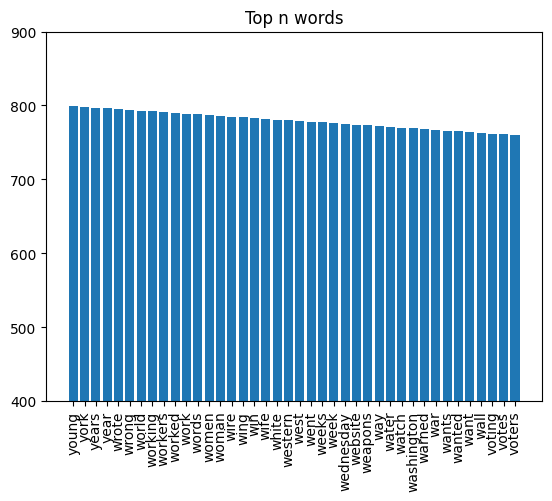

In [84]:
## Get top ten words to visualise
n = 40
top_words_from_countvec = countvect_df.sort_values('count', ascending = False).head(n)

## Plot
plt.bar(top_words_from_countvec['word'], top_words_from_countvec['count'])
plt.ylim([400, 800 + 100])
plt.xticks(rotation = 90)
plt.title("Top n words")
plt.show()

In [85]:
from sklearn.model_selection import train_test_split

y = df['label']  # Assuming 'label' is the column with fake/real labels
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [86]:
## Check dimensions

print('Train set ', X_train.shape)
print('Test set ', X_test.shape)

Train set  (35918, 800)
Test set  (8980, 800)


##First set: Use different models on BOW


##BOW 1: Logistic regression


In [87]:
## TRAIN
from sklearn.linear_model import LogisticRegression

s = time.time()
log_clf = LogisticRegression(max_iter=1000)  # Increased max_iter for convergence
log_clf.fit(X_train, y_train)
time_for_logreg = time.time() - s
print("Time to fit logistic regression :", time_for_logreg )

Time to fit logistic regression : 2.9965572357177734


In [88]:
## Evaluate

from sklearn.metrics import classification_report, confusion_matrix

y_pred_log = log_clf.predict(X_test)
print(classification_report(y_test, y_pred_log))

              precision    recall  f1-score   support

           0       0.98      0.99      0.98      4653
           1       0.99      0.98      0.98      4327

    accuracy                           0.98      8980
   macro avg       0.98      0.98      0.98      8980
weighted avg       0.98      0.98      0.98      8980



Text(50.722222222222214, 0.5, 'Real Labels')

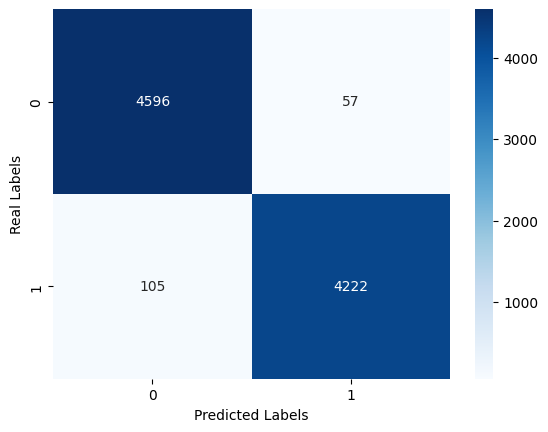

In [89]:
## Evaluate with Confusion Matrix
import seaborn as sns

sns.heatmap(confusion_matrix(y_test,y_pred_log), annot=True,
            fmt='', cmap='Blues')

plt.xlabel('Predicted Labels')
plt.ylabel('Real Labels')

##BOW2: SVM

SVM may be good for high dimensionality data, such as text that we are working on, with 800 predictors. In such cases we use linear kernels, and it is interesting to see if it gives similar results to Logistic regression.

In [90]:
from sklearn.svm import LinearSVC

linear_svc_clf = LinearSVC(max_iter = 100000) ##increase max iter to 100k for convergence
s = time.time()
linear_svc_clf.fit(X_train, y_train)
time_for_linear_svm = time.time() - s
print("Time to fit SVM :", time_for_linear_svm)

Time to fit SVM : 122.3295385837555


/usr/local/lib/python3.10/dist-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Time fitting SVM -- much longer than fitting a logistic regression, possibly due to the large feature space of the data.

In [91]:
## Evaluate
y_pred_svc = linear_svc_clf.predict(X_test)
print(classification_report(y_test, y_pred_svc))

              precision    recall  f1-score   support

           0       0.98      0.99      0.98      4653
           1       0.98      0.98      0.98      4327

    accuracy                           0.98      8980
   macro avg       0.98      0.98      0.98      8980
weighted avg       0.98      0.98      0.98      8980



Text(50.722222222222214, 0.5, 'Real Labels')

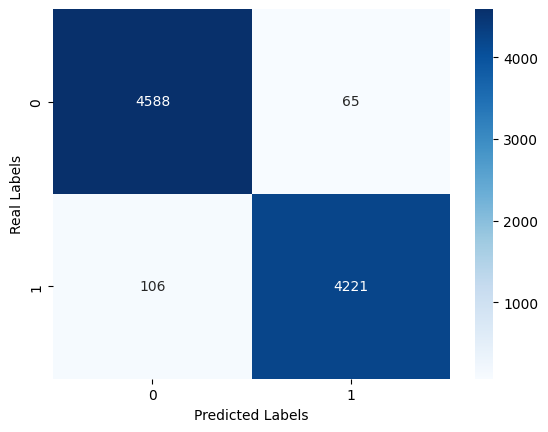

In [92]:
## Evaluate with Confusion Matrix

sns.heatmap(confusion_matrix(y_test,y_pred_svc), annot=True,
            fmt='', cmap='Blues')

plt.xlabel('Predicted Labels')
plt.ylabel('Real Labels')

Linear SVM vs Logistic Regression
Logistic regression fits to data much quicker
Accuracy is roughly the same

##BOW3: Random forests

For the forest, we will use 300 trees, and default values for the other hyperparameters

ceriterion: gini
max_depth = none, i.e. expanded until pure or less than min_samples_split
max_features = sqrt
Random forests work by bootstrapping the dataset to train slightly different trees, and then all the trees are combined to form an ensemble model, where the final decision is an equally weighted aggregate of the votes from all trees. The bootstrapping method, along with randomly selecting a subset of predictors to choose for for each split of the trees, help to decorrelate the trees such that they offer different insights into the data. Trees are usually fitted by finding the best feature and its best split at each branch of the tree and choosing the one that best minimises some cost function, such as entropy or gini impurity.

Random forests help to generalise an otherwise overfitted single decision tree.

In [93]:
from sklearn.ensemble import RandomForestClassifier
rf1 = RandomForestClassifier(n_estimators=300, n_jobs = -1)
print(rf1)

s = time.time()
rf1.fit(X_train, y_train)
time_for_rf_1 = time.time() - s
print("Time to fit RF :", time_for_rf_1)

RandomForestClassifier(n_estimators=300, n_jobs=-1)
Time to fit RF : 124.82520174980164


In [94]:
## Evaluate
y_pred_rf1 = rf1.predict(X_test)
print(classification_report(y_test, y_pred_rf1))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99      4653
           1       1.00      0.98      0.99      4327

    accuracy                           0.99      8980
   macro avg       0.99      0.99      0.99      8980
weighted avg       0.99      0.99      0.99      8980



Text(50.722222222222214, 0.5, 'Real Labels')

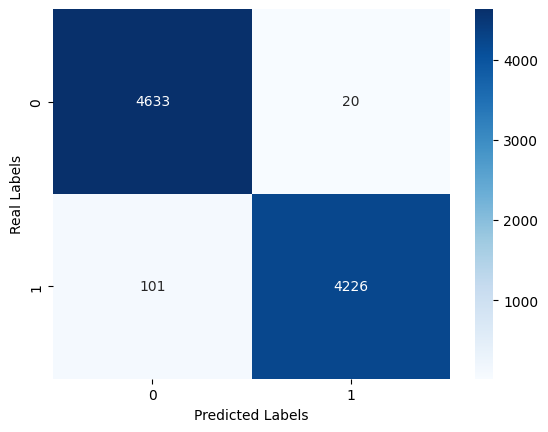

In [95]:
## Evaluate with Confusion Matrix

sns.heatmap(confusion_matrix(y_test,y_pred_rf1), annot=True,
            fmt='', cmap='Blues')

plt.xlabel('Predicted Labels')
plt.ylabel('Real Labels')

##BOW 3.2: Tuned RF

There are many hyperparameters to be tuned with random forests.

We will use random search (cross validation) instead of gridsearch, which may be faster and more efficient. This is done by randomly selecting points in the hyperparameter space, instead of using all of them.

In [96]:
from sklearn.model_selection import RandomizedSearchCV

In [97]:
## Set up hyperparameter space

param_grid = {
    'n_estimators' : [50, 150, 300, 450],
    'max_depth': [None, 10, 20, 40],
    'max_features': ['sqrt', 'log2']
}

In [98]:
## Reinstantiate
rf = RandomForestClassifier(random_state = 42)

## Fit the random search object (i.e. start fitting rfs) and find the best model
s = time.time()

## init the RandomizedSearchCV object as random_search, stating the grid of params to test
random_search = RandomizedSearchCV(estimator=rf, param_distributions=param_grid,
                                   n_iter=10, ## number of parameter settings being sampled (number of combinations being tried)
                                   cv=3, n_jobs=-1, verbose=2, random_state=42)
## fit the random search object
random_search.fit(X_train, y_train)
time_for_rf_2_hypertun = time.time() - s
print("Time for hyperparameter tuning via random search CV ", time_for_rf_2_hypertun)
best_rf = random_search.best_estimator_

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Time for hyperparameter tuning via random search CV  570.7013754844666


For the sake of saving time fitting the random search, we opt for 10 iterations i.e. 10 combinations tested



In [99]:
y_pred_rf2 = best_rf.predict(X_test)
print("Random Forest Results")
print(classification_report(y_test, y_pred_rf2))

Random Forest Results
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      4653
           1       0.99      0.99      0.99      4327

    accuracy                           0.99      8980
   macro avg       0.99      0.99      0.99      8980
weighted avg       0.99      0.99      0.99      8980



In [100]:
## For fair comparison, we want to also know the time taken to fit this new 'ideal' rf

# save tuned hyperparameters
best_params_rf_2 = random_search.best_params_

# then init the rf model with the best params
rf_2_tuned = RandomForestClassifier(**best_params_rf_2) ## need ** to unpack the dictionary

## Time the duration for fitting
s = time.time()
rf_2_tuned.fit(X_train, y_train)
time_for_rf_tuned = time.time() - s
print('Time to fit tuned rf ', time_for_rf_tuned)

Time to fit tuned rf  97.46920466423035


##Second set: Use different feature engineering -- TFIDF

TFIDF gives more weight to terms that are frequent in a particular document but not in many documents across the board, and is a different way of vectorising a particular document apart from BoW which just counts the number of terms that is in a specific document, disregarding how common/uncommon it is in others.



In [101]:
from sklearn.feature_extraction.text import TfidfVectorizer

## Use the TfidfVectorizer -- same parameters are before
vectoriser = TfidfVectorizer(min_df=100,
                             max_df=0.60,
                             stop_words='english',
                             max_features=800)

X = vectoriser.fit_transform(preprocessed_text)

y = df['label']
## Same train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 1. Log Reg
s = time.time()
log_clf = LogisticRegression(max_iter=1000)
log_clf.fit(X_train, y_train)
time_for_logreg_tfidf = time.time() - s
print("Time to fit logistic regression:", time_for_logreg_tfidf)

# 2. SVM Linear
s = time.time()
svm_linear_clf = LinearSVC(max_iter=1000)
svm_linear_clf.fit(X_train, y_train)
time_for_linear_svm_tfidf = time.time() - s
print("Time to fit SVM linear:", time_for_linear_svm_tfidf)


# Random Forest
s = time.time()
rf_clf = RandomForestClassifier()
rf_clf.fit(X_train, y_train)
time_for_untuned_rf_tfidf = time.time() - s
print("Time to fit Random Forest:", time_for_untuned_rf_tfidf)

Time to fit logistic regression: 0.5730183124542236
Time to fit SVM linear: 0.4801781177520752
Time to fit Random Forest: 62.728803396224976


In [102]:
## Evaluation
## Log reg
y_pred_log = log_clf.predict(X_test)
print("Logistic Regression Results")
print(classification_report(y_test, y_pred_log))

## SVM
y_pred_svm = svm_linear_clf.predict(X_test)
print("SVM Linear Results")
print(classification_report(y_test, y_pred_svm))

## RF
y_pred_rf = rf_clf.predict(X_test)
print("Random Forest Results")
print(classification_report(y_test, y_pred_rf))

Logistic Regression Results
              precision    recall  f1-score   support

           0       0.98      0.98      0.98      4653
           1       0.98      0.98      0.98      4327

    accuracy                           0.98      8980
   macro avg       0.98      0.98      0.98      8980
weighted avg       0.98      0.98      0.98      8980

SVM Linear Results
              precision    recall  f1-score   support

           0       0.98      0.98      0.98      4653
           1       0.98      0.98      0.98      4327

    accuracy                           0.98      8980
   macro avg       0.98      0.98      0.98      8980
weighted avg       0.98      0.98      0.98      8980

Random Forest Results
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      4653
           1       1.00      0.97      0.99      4327

    accuracy                           0.99      8980
   macro avg       0.99      0.99      0.99      8980
weigh

In [103]:
## Time to train, manually save since I forgot to do so when fitting

## Model prediction results
acc_bow_logreg = .98
acc_bow_svm = .98
acc_bow_rf_untuned = .99
acc_bow_rf_tuned = .99
acc_tfidf_logreg = .98
acc_tfidf_svm = .98
acc_tfidf_rf_untuned = .99

In [104]:
import pandas as pd

model_comparisons = pd.DataFrame({
    'Vector_type' : ['BOW']*4 + ['TFIDF']*3,
    'Model': ["Logistic reg", 'SVM', 'RF', 'RF tuned', 'Logistic reg', 'SVM', 'RF'],
    'Time_to_fit' : [time_for_logreg, time_for_linear_svm, time_for_rf_1, time_for_rf_tuned, time_for_logreg_tfidf, time_for_linear_svm_tfidf, time_for_untuned_rf_tfidf],
    'Accuracy_score' : [acc_bow_logreg, acc_bow_svm, acc_bow_rf_untuned, acc_bow_rf_tuned, acc_tfidf_logreg, acc_tfidf_svm, acc_tfidf_rf_untuned],
    'No_words_predictors' : 800
}
)

In [105]:
print(model_comparisons.sort_values('Time_to_fit', ascending = True))

  Vector_type         Model  Time_to_fit  Accuracy_score  No_words_predictors
5       TFIDF           SVM     0.480178            0.98                  800
4       TFIDF  Logistic reg     0.573018            0.98                  800
0         BOW  Logistic reg     2.996557            0.98                  800
6       TFIDF            RF    62.728803            0.99                  800
3         BOW      RF tuned    97.469205            0.99                  800
1         BOW           SVM   122.329539            0.98                  800
2         BOW            RF   124.825202            0.99                  800


What if we had reduced the number of words/predictors to 400 (i.e. halving the number of columns)?

Will this still be enough information for our models to perform well?

##BOW (400 predictors)


In [106]:
## Create instance of BOW vectoriser
bow_vectoriser = CountVectorizer(min_df = 100, ## require a word to be in at least 100 documents
                            max_df = 0.60, ## is a word appears in 60% or more of documents, then ignore, since it may be too common
                            stop_words = 'english', ## use stopwords again, although we had used it from spacy already
                            max_features = 400) ## now half only

## Apply vectorisers to data
X = bow_vectoriser.fit_transform(preprocessed_text)

## Check shape
print(X.shape)

## Train test split
y = df['label']  # Assuming 'label' is the column with fake/real labels
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## FIT LOG REG MODEL ==========================================================
s = time.time()
log_clf_reduced_preds = LogisticRegression(max_iter=1000)  # Increased max_iter for convergence
log_clf_reduced_preds.fit(X_train, y_train)
print("Time to fit logistic regression :", time.time() - s)

(44898, 400)
Time to fit logistic regression : 1.7340924739837646


In [107]:
## EVALUATE LOG REG MODEL --------------------------------------------------------
from sklearn.metrics import classification_report
y_pred_log_reg_reduced_preds = log_clf_reduced_preds.predict(X_test)
print(classification_report(y_test, y_pred_log_reg_reduced_preds))

              precision    recall  f1-score   support

           0       0.97      0.98      0.98      4653
           1       0.98      0.97      0.98      4327

    accuracy                           0.98      8980
   macro avg       0.98      0.98      0.98      8980
weighted avg       0.98      0.98      0.98      8980



##TFIDF (400 predictors)


In [108]:
from sklearn.feature_extraction.text import TfidfVectorizer

## Use the TfidfVectorizer -- same parameters are before
vectoriser = TfidfVectorizer(min_df=100,
                             max_df=0.60,
                             stop_words='english',
                             max_features=400)

X = vectoriser.fit_transform(preprocessed_text)

y = df['label']
## Same train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 1. Log Reg
s = time.time()
log_clf = LogisticRegression(max_iter=1000)
log_clf.fit(X_train, y_train)
print("Time to fit logistic regression:", time.time() - s)

Time to fit logistic regression: 0.5647704601287842


In [109]:
## EVALUATE LOG REG MODEL --------------------------------------------------------
from sklearn.metrics import classification_report
y_pred_log_reg_reduced_preds = log_clf.predict(X_test)
print(classification_report(y_test, y_pred_log_reg_reduced_preds))

              precision    recall  f1-score   support

           0       0.97      0.97      0.97      4653
           1       0.97      0.97      0.97      4327

    accuracy                           0.97      8980
   macro avg       0.97      0.97      0.97      8980
weighted avg       0.97      0.97      0.97      8980



When feature space was reduced by half,
Logistic regression did not really suffer much in terms of time taken to fit or accuracy
TFIDF seemed to work better (slightly) than BOW, and this makes sense since TFIDF captures more information than BOW

##Word embedding methods


Instead of using methods that vectorise the documents based on words, essentially treating words to be independent (as independent predictors), we try to capture some semantics and meanings of the words instead to see if we can improve the model.



1. Using pre-trained word embeddings
We will try to use the GloVe model. GloVe was developed for generating word embeddings, and designed to get semantic relationships between words. Therefore in this space, words with similar meanings will tend to be closer in this new feature space.

In [110]:
import gensim.downloader

glove_model = gensim.downloader.load('glove-wiki-gigaword-100')

[==================================================] 100.0% 128.1/128.1MB downloaded


In [111]:
## Check some stuff from glove
print('Vector sizes are ', glove_model.vector_size) ## 100 dim for feature space -- just nice?

Vector sizes are  100


Our feature space is 100 dimensions -- when compared to the dimensions of BoW and TFIDF where we had chosen to include about 800 words (dimensions), this is considered small



We can test this out by checking the cosine similarity (how similar two words are in the feature space).



In [112]:
## Test it out -- get word vectors
word_vec =glove_model['word']
sent_vec =glove_model['sentence']

## shape
glove_model['word'].shape ## 100 column space that the words exist in

## Test similarity
print('cosine sim between "word" and "sentence" ', glove_model.cosine_similarities(word_vec, [sent_vec]))
print('cosine sim between "word" and "potato" ', glove_model.cosine_similarities(word_vec, [glove_model['potato']]))

## Test on multiple words
glove_model.cosine_similarities(word_vec, [glove_model['potato'],
                                          glove_model['car'],
                                          glove_model['language']])

## Test on the word banana
glove_model.cosine_similarities(glove_model['banana'], [glove_model['apple'],
                                                       glove_model['food'],
                                                       glove_model['object'],
                                                       glove_model['computers']])
## result -- the words get less and less related

cosine sim between "word" and "sentence"  [0.4031449]
cosine sim between "word" and "potato"  [0.2914069]


array([0.5054469 , 0.4017795 , 0.04679427, 0.08940844], dtype=float32)

cosine sim between "word" and "sentence"  [0.4031449]
cosine sim between "word" and "potato"  [0.2914069]


array([0.5054469 , 0.4017795 , 0.04679427, 0.08940844], dtype=float32)

In [114]:
## Checking that word exists in the vocab
glove_vocab = glove_model.key_to_index

## Check type
print(type(glove_vocab)) ## glove_vocab is a dictionary instead of a list

## Get vocab size
print('Size of vocab ', len(glove_vocab)/1000, ' thousand')

## See some words
list_of_keys = list(glove_vocab.keys())
list_of_values = list(glove_vocab.values())

<class 'dict'>
Size of vocab  400.0  thousand


In [115]:
## Take a peek at the keys and values of the vocab
print(list_of_keys[0:10])
print(list_of_values[0:10])

['the', ',', '.', 'of', 'to', 'and', 'in', 'a', '"', "'s"]
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


Interestingly, punctuations also have embeddings, as seen above. Let us take a closer look at those embeddings and find similar 'tokens' to the punctuations.

In [116]:
import numpy as np

## Word embedding for comma
glove_model[',']
## Cosine similarities btn punctuations
print('Cos sim btn "," and "." ', np.dot(glove_model[','], glove_model['.']))
print('Cos sim btn "," and "?" ', np.dot(glove_model[','], glove_model['?']))

## Cosine similarities btn punctuations and words
print('Cos sim btn "," and "hello" ', np.dot(glove_model[','], glove_model['hello']))
print('Cos sim btn "," and "pause" ', np.dot(glove_model[','], glove_model['pause']))
print('Cos sim btn "," and "comma" ', np.dot(glove_model[','], glove_model['pause']))

Cos sim btn "," and "."  26.550135
Cos sim btn "," and "?"  20.919863
Cos sim btn "," and "hello"  4.4000187
Cos sim btn "," and "pause"  5.9220767
Cos sim btn "," and "comma"  5.9220767


In [117]:
## Most similar terms to comma
glove_model.similar_by_word(",")

[('and', 0.8781740665435791),
 ('.', 0.8755987882614136),
 ('while', 0.8525034785270691),
 ('but', 0.8338185548782349),
 ('as', 0.8283949494361877),
 ('also', 0.8065630197525024),
 ('now', 0.8026498556137085),
 ('well', 0.8003395199775696),
 ('one', 0.7802436947822571),
 ('with', 0.779920220375061)]

##Third feature engineering: use the average word embedding of the sentence from GloVe


First, we need to turn the texts into word vectors, since each text has multiple words. This would result in many vectors -- for simplicity, we will take the average of the vectors to result in a single vector for each text. This has some limitations, since it may 'dilute' the meaning of certain important words, but we will go ahead with this for now.

In [118]:
def get_avg_embedding(text): ## Takes in a single text, instead of a list of texts
    ## Tokenise first, get indiv words
    words = text.split()

    ## Get list of word vectors (this would result in many word vectors)
    vectors = [glove_model[word] for word in words if word in glove_vocab] ## make sure that the word is covered by the model

    ## Normalise the vectors for each word
    normalised_vectors = [vector/np.linalg.norm(vector) for vector in vectors] if vectors else None ## If there was no vector in vectors, then return None

    ## Take the average of all
    avg_vector = sum(normalised_vectors)/len(normalised_vectors) if normalised_vectors else None

    return(avg_vector)

## Since we allowed for None in cases where there was no vector (this happens if
# the text had no words that was recognised by the Glove Model), we should make sure
# to check the list of avg embeddings to see if there are empty vectors

In [119]:
s = time.time()
avg_embeddings_X = [get_avg_embedding(text) for text in preprocessed_texts]
print('Time taken to get avg embeddings, via list comprehension method', time.time()- s)

Time taken to get avg embeddings, via list comprehension method 88.74562764167786


This is essentially using a for loop in the list comprehension, which is very slow. A faster way would be to use a parallelised method, under the package 'pandarallel', that complements the Pandas framework. Let us see if it is faster.

In [120]:
pip install pandarallel

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.3/115.3 kB 3.1 MB/s eta 0:00:00
  Created wheel for pandarallel: filename=pandarallel-1.6.5-py3-none-any.whl size=16672 sha256=d03f3ef9575e4e486857e12d97f6bc9f2ffa6890516959e0c087427c96b7a261
  Stored in directory: /root/.cache/pip/wheels/50/4f/1e/34e057bb868842209f1623f195b74fd7eda229308a7352d47f
Successfully built pandarallel


In [121]:
from pandarallel import pandarallel

pandarallel.initialize(progress_bar=True)

INFO: Pandarallel will run on 1 workers.
INFO: Pandarallel will use Memory file system to transfer data between the main process and workers.


In [122]:
s = time.time()
df['avg_embeddings'] = df.Full_text_cleaned.parallel_apply(get_avg_embedding)
time_for_pandarallel = time.time() - s
print('Time taken to get avg embeddings, via pandarallel method', time_for_pandarallel)

Time taken to get avg embeddings, via pandarallel method 93.23342156410217


In [123]:
print('Percentage decrease in time taken ', (172 - time_for_pandarallel)/172 * 100, ' %')

Percentage decrease in time taken  45.794522346452226  %


Therefore pandarallel makes a significant reduction in time taken to get the average vector representation of the text.

Check results of the embedding process

In [124]:
print(type(avg_embeddings_X))
print(len(avg_embeddings_X)) ## this is the number of documents

## Look at one of the embeddings
print(type(avg_embeddings_X[0])) ## List of np.arrays
avg_embeddings_X[0].shape ## Each embedding has 100 length, as expected

<class 'list'>
44898
<class 'numpy.ndarray'>


(100,)

In [125]:
## Check if any vector is empty or None

## Recall that if the words in our text dont exist in the glove vocab, the function returns None
## Test the function on some gibberish and see if it returns None
print(get_avg_embedding("sdjfas fasdfjsdfsajfls"))

## Check if there are any None(s) in our result (from the df version)
print("None in DF ", df.avg_embeddings.isna().sum())

## Check again from the list version
print("None in list ", sum(1 for vec in avg_embeddings_X if vec is None))

None
None in DF  9
None in list  9


Turns out that there are missing vectors, possibly due to unrecgonised words. Let us take a closer look at them



In [126]:
df[df.avg_embeddings.isna()][['Full_text', 'Full_text_cleaned', 'label', 'avg_embeddings']]

,Full_text,Full_text_cleaned,label,avg_embeddings
755,https://fedup.wpengine.com/wp-content/uploads/...,,0,None
2345,https://fedup.wpengine.com/wp-content/uploads/...,,0,None
2785,https://100percentfedup.com/served-roy-moore-v...,,0,None
17952,https://100percentfedup.com/12-yr-old-black-co...,,0,None
18209,https://100percentfedup.com/video-hillary-aske...,,0,None
19046,https://fedup.wpengine.com/wp-content/uploads/...,,0,None
37835,https://fedup.wpengine.com/wp-content/uploads/...,,0,None
39073,https://fedup.wpengine.com/wp-content/uploads/...,,0,None
44008,https://fedup.wpengine.com/wp-content/uploads/...,,0,None


We see that they are either empty since they were URL links that have been cleared by the preprocessing phase (e.g. removing non alphanumeric terms, removing stopwords) or just trivial one word cases. We can remove them

In [127]:
## Drop NAs/ Nones
print(df.shape)
print(df.dropna(subset = ['avg_embeddings']).shape) ## 9 removed

## Drop
data_no_nas = df.dropna(subset = ['avg_embeddings'])

## Check
print(data_no_nas.head())

(44898, 9)
(44889, 9)
                                               title  \
0  JIMMY KIMMEL: A Politically Correct Thanksgivi...   
1  State Department OKs possible sale to Canada o...   
2  HILLARY Calls On CRANKY SOCIALIST She Stole El...   
3   Anti-Gay Texas Attorney General Faces Disbarment   
4  Bernie Sanders: When you’re White, you don’t k...   

                                                text       subject  \
0                                                         politics   
1  WASHINGTON (Reuters) - The U.S. State Departme...  politicsNews   
2  Poor Bernie. He s been a public servant his wh...      politics   
3  The Texas Bar Association is stepping up to th...          News   
4  Bernie Sanders is so focused on pandering to b...      politics   

                  date  label  \
0         Nov 23, 2016      0   
1  September 12, 2017       1   
2         Sep 29, 2016      0   
3    February 11, 2016      0   
4          Mar 7, 2016      0   

                     

##Repeat modelling workflow : train test split and fitting on the new X vector embeddings data


In [128]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

## Rmb to use the data without nas, so that there is no inconsistency in the set of X vectors
X = data_no_nas.avg_embeddings.to_list()

y = data_no_nas['label']
## Same train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Check if the data is prepared correctly/ in the right format
print(type(X_train)) ## this is a list -- need to convert to np array
print(type(y_train))

<class 'list'>
<class 'pandas.core.series.Series'>


Currently, our X data is in the form of list of lists. In order to feed into the sklearn algorithms, we need to first convert it to 2D np arrays.

In [129]:
print(len(X_train))

## Convert to 2D np arrays
X_train = np.array(X_train)
X_test = np.array(X_test)

## Check shape
print(X_train.shape)
print(X_test.shape) ## our data is now in 2D arrays, so it is okay

35911
(35911, 100)
(8978, 100)


In [130]:
# 1. Log Reg
s = time.time()
log_clf = LogisticRegression(max_iter=1000)
log_clf.fit(X_train, y_train)
time_for_logreg_glove = time.time() - s
print("Time to fit logistic regression:", time_for_logreg_glove)

# 2. SVM Linear
s = time.time()
svm_linear_clf = LinearSVC(max_iter=1000)
svm_linear_clf.fit(X_train, y_train)
time_for_linear_svm_glove = time.time() - s
print("Time to fit SVM linear:", time_for_linear_svm_glove)


# Random Forest
s = time.time()
rf_clf = RandomForestClassifier()
rf_clf.fit(X_train, y_train)
time_for_untuned_rf_glove = time.time() - s
print("Time to fit Random Forest:", time_for_untuned_rf_glove)

Time to fit logistic regression: 0.42124176025390625
Time to fit SVM linear: 0.8232128620147705
Time to fit Random Forest: 48.57770013809204


In [131]:
## Model evaluations
print(classification_report(log_clf.predict(X_test), y_test))
print(classification_report(svm_linear_clf.predict(X_test), y_test))
print(classification_report(rf_clf.predict(X_test), y_test))

              precision    recall  f1-score   support

           0       0.92      0.93      0.93      4655
           1       0.92      0.92      0.92      4323

    accuracy                           0.92      8978
   macro avg       0.92      0.92      0.92      8978
weighted avg       0.92      0.92      0.92      8978

              precision    recall  f1-score   support

           0       0.94      0.94      0.94      4661
           1       0.94      0.93      0.94      4317

    accuracy                           0.94      8978
   macro avg       0.94      0.94      0.94      8978
weighted avg       0.94      0.94      0.94      8978

              precision    recall  f1-score   support

           0       0.96      0.94      0.95      4794
           1       0.93      0.96      0.95      4184

    accuracy                           0.95      8978
   macro avg       0.95      0.95      0.95      8978
weighted avg       0.95      0.95      0.95      8978



##Results of GloVe representations

Although much faster to fit the models, we suffer quite a bit in terms of accuracy scores.

Nature of representation
While BoW and TFIDF capture the occurance of words independently, the glove method we used essentially took the 'center' of the word embedded vectors of each text, since we took their average. This might end up cancelling out some of the meaning of the words, losing out on granularity. It is also possible that some of the words, which were crucial in determining the outcome of the text in being real or false news, were not in the vocabulary of the glove model and thus not factored into the data, which will cause a loss of importasnt information.

##Converting text to sequences with Keras, with embedding layer in the neural network

How it works:

integer encoding: the text_to_sequences method converts texts to integers based on the vocabulary of the corpus.

we then have a sequence of integers (text to sequences), since models cannot understand words but only numbers

we pad each vector such that there is a consistent number of integers

the first layer of the neural network will be the embedding layer, which is a special kind of layer that looks up each integer (word index) and maps it to a dense vector, which is the semantic representation, same as the one we used with GloVe.

then we connect to a fully connected layer, where the last layer will be a single neuron with a sigmoid activation function - since we are making a binary classification

In [132]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [133]:
## Instantiate the keras tokenizer

tokenizer = Tokenizer(num_words=10000, oov_token = '<00v>') ## this is for out of vocab
## terms -- therefore when testing, if the model sees a word that has not been trained,
## it will map it to 1 instead of removing the term

## Fit the tokenizer to the corpus
tokenizer.fit_on_texts(df.Full_text_cleaned) ## use fit on texts method as we have a series or list of texts
word_index = tokenizer.word_index

 The fit on text method updates the internal vocab based on a list of texts, creating a vocab index based on word frequency, then the texts to sequences transforms each text in texts to a sequence of inters

##Converting text to sequences with Keras, with embedding layer in the neural network

How it works:

integer encoding: the text_to_sequences method converts texts to integers based on the vocabulary of the corpus.

we then have a sequence of integers (text to sequences), since models cannot understand words but only numbers

we pad each vector such that there is a consistent number of integers

the first layer of the neural network will be the embedding layer, which is a special kind of layer that looks up each integer (word index) and maps it to a dense vector, which is the semantic representation, same as the one we used with GloVe.

then we connect to a fully connected layer, where the last layer will be a single neuron with a sigmoid activation function - since we are making a binary classification

In [134]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

## Instantiate the keras tokenizer

tokenizer = Tokenizer(num_words=10000, oov_token = '<00v>') ## this is for out of vocab
## terms -- therefore when testing, if the model sees a word that has not been trained,
## it will map it to 1 instead of removing the term

print(tokenizer)

In [135]:
from sklearn.model_selection import train_test_split
import time
## Following the same split from the previous exercise
X_train_texts, X_test_texts, y_train, y_test = train_test_split(df.Full_text_cleaned, df.label, test_size=0.2, random_state=42)
## Fit the tokenizer to the corpus

s = time.time()
tokenizer.fit_on_texts(X_train_texts) ## use fit on texts method as we have a series or list of texts
time_to_tokenize = time.time() -s
print('Time taken to tokenize {:.2f}'.format(time_to_tokenize))
word_index = tokenizer.word_index

Time taken to tokenize 7.15


In [136]:
## Check the word_index
print(type(word_index))

## See a few examples
print(type(word_index.items()))

## Save as a list and see some examples
list(word_index.items())[0:10]

<class 'dict'>
<class 'dict_items'>


[('<00v>', 1),
 ('trump', 2),
 ('said', 3),
 ('president', 4),
 ('would', 5),
 ('people', 6),
 ('one', 7),
 ('state', 8),
 ('new', 9),
 ('also', 10)]

For the key-value pairs in word_index, the keys are the vocabulary, and the values are the rank according to word frequency.

Once again, the tokenising step examines the entire corpus and builds a dictionary. This will help us map words to integers later down the line.


In [137]:
print(len(word_index)) ## our vocab size is about 100k+


105080


Turning to sequences, and then padding

In [141]:
## we use the tokenizer that has already been fitted on a (training) corpus, to do the
## sequencing based on that corpus
sequences = tokenizer.texts_to_sequences(df.Full_text_cleaned)

In [142]:
## check sequences
print(type(sequences))

## check examples
print(sequences[0])
print("=========================\n")
print(sequences[1])

<class 'list'>
[3475, 4749, 1621, 1786, 7128, 8982, 98]

[8, 90, 1, 336, 2675, 1177, 223, 84, 1, 15, 8, 90, 1109, 336, 2675, 1177, 3473, 3469, 455, 1227, 1772, 223, 1351, 209, 3, 91, 100, 262, 42, 1334, 209, 3, 5800, 103, 124, 336, 2675, 1177, 1601, 1, 3473, 1928, 2490, 78, 1, 1731, 3, 4622, 3872, 3577, 837, 1, 1, 2191, 1, 837, 126, 3616]


In [144]:
## See the lengths of first 10 documents
[len(text) for text in sequences[0:10]]

## Get entire list of lengths
lengths_of_texts =  [len(text) for text in sequences]

## Range of values
print("Max length is {}".format(np.max(lengths_of_texts)))
print("Min length is {}".format(np.min(lengths_of_texts)))
print("Mean and median are {:.2f}, {}".format(np.mean(lengths_of_texts), np.median(lengths_of_texts)))

Max length is 4898
Min length is 0
Mean and median are 236.71, 210.0


Visualise the distribution of lengths. This is also why we have to perform padding, so that we can fit a consistent set of inputs into the neural network

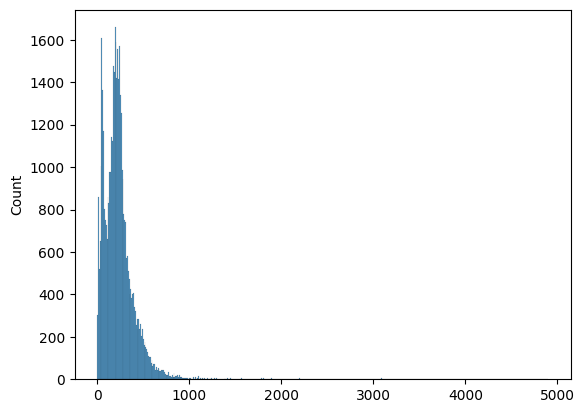

In [145]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(lengths_of_texts)
plt.show()

We can see that the distribution of lengths of the texts differ greatly but is also very very right skewed, i.e. most of the text lengths exist somewhere between 0 and 1000, but a few stretch up till 5k in length.

In [149]:
## Distribution of lengths -- anomalies
df['text_length'] = df.Full_text_cleaned.str.len()
anomalies = df.text_length > 2500
print('Number of texts with more than 2500:  {}'.format(sum(anomalies)))
percent_anom = sum(anomalies)/len(df)
print('Percentage of texts with more than 2500:  {:.2f}'.format(percent_anom))

## anomalies
df[anomalies][['Full_text_cleaned', 'text_length', 'label']]

## distribution of lengths across labels
df[anomalies].value_counts('label')

Number of texts with more than 2500:  8333
Percentage of texts with more than 2500:  0.19


label
1    4834
0    3499
dtype: int64

In [150]:
## Get sequences for train and test input data
X_train_seq = tokenizer.texts_to_sequences(X_train_texts)
X_test_seq = tokenizer.texts_to_sequences(X_test_texts)

Value for maxlen -- choose average length of all text
Instead of using the default, which ie 'None' and would result in padding up to the max length of our train set -- which can up to 5k -- would give us too large a dimension. Instead we use the average length first, which is about 300.

In [151]:
## Padding
from tensorflow.keras.preprocessing.sequence import pad_sequences

## For length to pad till, we use the average length of all texts
avg_length_text = int(np.mean(lengths_of_texts))

X_train_pad = pad_sequences(X_train_seq, maxlen=avg_length_text, padding='post', truncating='post')
X_test_pad = pad_sequences(X_test_seq, maxlen=avg_length_text, padding='post', truncating='post')

In [152]:
## Check results of padding
print(X_train_pad.shape)
print(X_test_pad.shape)

(35918, 236)
(8980, 236)


In [153]:
## See some examples
print(X_train_pad[0:5])

[[2446  481  824 ...  174 3188    2]
 [   9 1839 2348 ...    0    0    0]
 [   1  872  464 ...    0    0    0]
 [ 147   33  464 ...    0    0    0]
 [3367 1656 1400 ...    0    0    0]]


##Model 1 : Simple neural network with embedding layer

For our first model, we will use:

Architecture: Basic fully connected neural network

Embedding layer at the start
1 Hidden layer (16 neurons)
Batch normalisation -- helps with convergence (stabilises training by making sure the intermediate layer activations are non-shifting, i.e. internal covariate shift)
Others

Early stopping (patience = 10) -- reduces overfitting
Mini batch training (below)
Adam optimiser: adaptive learning rate optimiser that adjusts the LR based on historical gradients -- i.e. if the gradients have been large, then the LR will be large as well to take advantage of 'steeper slopes'

In [154]:
print(X_train_pad.shape)
y_train.shape

(35918, 236)


(35918,)

Recall that we have 35k training instances, hence one full epoch might take a while to complete. We can add mini-batch gradient descent to speed up the training time.

In [155]:
import tensorflow as tf
print("Num GPUs Available: ", len(tf.config.experimental.list_physical_devices('GPU')))

Num GPUs Available:  0


In [156]:
from keras.models import Sequential # for the model
from keras.layers import Embedding, Flatten, Dense, BatchNormalization ## for the layers
from keras.callbacks import EarlyStopping # for tailoring early stopping, to reduce overfitting

# Define the model
model = Sequential([
    Embedding(input_dim=len(word_index), # input dimension = size of vocab
              output_dim=16, # allow the embedded space to have 16 dimensions
              input_length=avg_length_text), # input length = length of sequences
    Flatten(), # this will flatten to a layer with 307 x 16 neurons
    Dense(16, activation='relu'),
    BatchNormalization(), # Add batch normalization here
    Dense(1, activation='sigmoid')  # Binary classification
])

# Compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Early stopping with a patience of 10 epochs (you can adjust this as needed)
early_stop = EarlyStopping(monitor='val_loss', patience=10)

# Train the model -- save history so that we can plot fitting history, such as loss and accuracy
history = model.fit(X_train_pad, y_train, epochs=100, # increased epochs as early stopping will determine when to stop
                    batch_size = 200, # for faster training
                    validation_data=(X_test_pad, y_test),
                    callbacks=[early_stop]) # Add the early stopping callback here

Epoch 1/100
180/180 [==============================] - 11s 47ms/step - loss: 0.1398 - accuracy: 0.9393 - val_loss: 0.2489 - val_accuracy: 0.9905
Epoch 2/100
180/180 [==============================] - 6s 32ms/step - loss: 0.0077 - accuracy: 0.9991 - val_loss: 0.0441 - val_accuracy: 0.9953
Epoch 3/100
180/180 [==============================] - 6s 31ms/step - loss: 0.0025 - accuracy: 0.9999 - val_loss: 0.0159 - val_accuracy: 0.9952
Epoch 4/100
180/180 [==============================] - 6s 36ms/step - loss: 0.0013 - accuracy: 1.0000 - val_loss: 0.0142 - val_accuracy: 0.9949
Epoch 5/100
180/180 [==============================] - 5s 30ms/step - loss: 8.1797e-04 - accuracy: 1.0000 - val_loss: 0.0138 - val_accuracy: 0.9951
Epoch 6/100
180/180 [==============================] - 7s 37ms/step - loss: 5.7361e-04 - accuracy: 1.0000 - val_loss: 0.0135 - val_accuracy: 0.9952
Epoch 7/100
180/180 [==============================] - 6s 31ms/step - loss: 3.4386e-04 - accuracy: 1.0000 - val_loss: 0.0135 - 

In [157]:
## History for the important information that was saved during fitting
print(type(history.history))
print((history.history.keys())) ## these are the information that we can visualise

<class 'dict'>
dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])


##Visualise fitting process


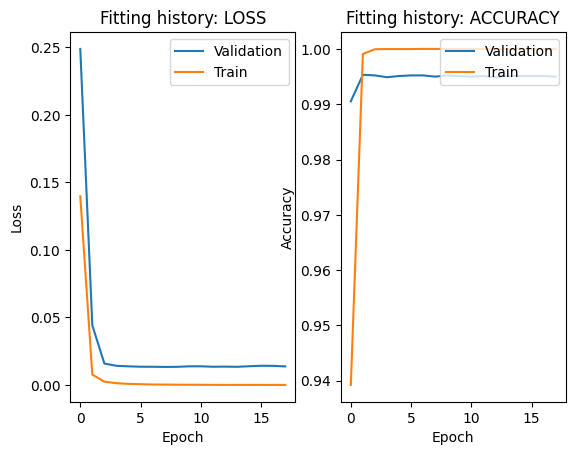

In [158]:
plt.subplot(1,2,1)
plt.plot(history.history['val_loss']) ## validation loss
plt.plot(history.history['loss']) ## training loss (should be decreasing)
plt.title("Fitting history: LOSS")
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Validation', 'Train'], loc = 'upper right')

plt.subplot(1,2,2)
plt.plot(history.history['val_accuracy']) ## validation loss
plt.plot(history.history['accuracy']) ## training loss (should be decreasing)
plt.title("Fitting history: ACCURACY")
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Validation', 'Train'], loc = 'upper right')


plt.show()

##Evaluate Model 1


In [159]:
## Test set
loss, accuracy = model.evaluate(X_test_pad, y_test)
print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

281/281 [==============================] - 2s 6ms/step - loss: 0.0137 - accuracy: 0.9950
Test Loss: 0.013744579628109932
Test Accuracy: 0.9949888586997986


In [160]:
## Train set
final_train_loss = history.history['loss'][-1]
final_train_accuracy = history.history['accuracy'][-1]

final_val_loss = history.history['val_loss'][-1]
final_val_accuracy = history.history['val_accuracy'][-1]

print("Final Training Loss:", final_train_loss)
print("Final Training Accuracy:", final_train_accuracy)
print("Final Validation Loss:", final_val_loss)
print("Final Validation Accuracy:", final_val_accuracy)

Final Training Loss: 3.611789725255221e-05
Final Training Accuracy: 1.0
Final Validation Loss: 0.013744579628109932
Final Validation Accuracy: 0.9949888586997986


We can see that the evaluation on the test set is the same as the evaluation on the validation set from the fitting process, since we added our test set as the validation data during the training.

##Outcome

We can see that our training accuracy is really high, compared to our validation accuracy. This could be the presence of overfitting. We can take steps to reduce this in the next **model**

##Model 1.1
Some changes to the model that we can test out

REDUCE EMBEDDING VECTOR DIMENSION -- from 16 to 10
Adding a dropout layer

In [161]:
from keras.layers import Dropout


model_2 = Sequential([
    Embedding(input_dim=len(word_index), output_dim=10, input_length=avg_length_text),
    Flatten(),
    Dense(10, activation='relu'),  # Matched with embedding output dim
    Dropout(0.5),  # Adding dropout
    Dense(1, activation='sigmoid')
])

model_2.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history_2 = model.fit(X_train_pad, y_train, epochs=50, batch_size=200, validation_data=(X_test_pad, y_test), callbacks=[early_stopping])

Epoch 1/50
180/180 [==============================] - 9s 51ms/step - loss: 3.4546e-05 - accuracy: 1.0000 - val_loss: 0.0143 - val_accuracy: 0.9951
Epoch 2/50
180/180 [==============================] - 6s 32ms/step - loss: 3.0618e-05 - accuracy: 1.0000 - val_loss: 0.0146 - val_accuracy: 0.9952
Epoch 3/50
180/180 [==============================] - 6s 32ms/step - loss: 2.5618e-05 - accuracy: 1.0000 - val_loss: 0.0145 - val_accuracy: 0.9952
Epoch 4/50
180/180 [==============================] - 6s 34ms/step - loss: 2.2524e-05 - accuracy: 1.0000 - val_loss: 0.0147 - val_accuracy: 0.9952
Epoch 5/50
180/180 [==============================] - 6s 34ms/step - loss: 1.9566e-05 - accuracy: 1.0000 - val_loss: 0.0144 - val_accuracy: 0.9952
Epoch 6/50
180/180 [==============================] - 6s 36ms/step - loss: 1.8368e-05 - accuracy: 1.0000 - val_loss: 0.0149 - val_accuracy: 0.9954
Epoch 7/50
180/180 [==============================] - 5s 29ms/step - loss: 1.4301e-05 - accuracy: 1.0000 - val_loss: 0

##Evaluate model 2


In [162]:
final_train_loss_2 = history_2.history['loss'][-1]
final_train_accuracy_2 = history_2.history['accuracy'][-1]

final_val_loss_2 = history_2.history['val_loss'][-1]
final_val_accuracy_2 = history_2.history['val_accuracy'][-1]

print("Final Training Loss:", final_train_loss_2)
print("Final Training Accuracy:", final_train_accuracy_2)
print("Final Validation Loss:", final_val_loss_2)
print("Final Validation Accuracy:", final_val_accuracy_2)

Final Training Loss: 9.386500096297823e-06
Final Training Accuracy: 1.0
Final Validation Loss: 0.015116334892809391
Final Validation Accuracy: 0.9952116012573242


The validation accuracy has not changed much, whereas the training accuracy is still really high. We can try one last round of increasing regularisation

##Model 1.3
Reduce embedding dimension further (to 8)
Add some L2 regularisation (regularisation penalty hyperparameter set to 0.01)

In [163]:
from keras.layers import Dropout
from keras.regularizers import l2

model_3 = Sequential([
    Embedding(input_dim=len(word_index), output_dim=8, input_length=avg_length_text),
    Flatten(),
    Dense(8, activation='relu', kernel_regularizer=l2(0.01)),  # L2 regularization
    Dropout(0.5),  # Adding dropout
    Dense(1, activation='sigmoid')
])

model_3.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

## Decrease patience, allow restore to best weights during patience
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history_3 = model_3.fit(X_train_pad, y_train, epochs=50, batch_size=200, validation_data=(X_test_pad, y_test), callbacks=[early_stopping])

Epoch 1/50
180/180 [==============================] - 5s 19ms/step - loss: 0.5177 - accuracy: 0.7972 - val_loss: 0.2237 - val_accuracy: 0.9822
Epoch 2/50
180/180 [==============================] - 3s 17ms/step - loss: 0.2456 - accuracy: 0.9231 - val_loss: 0.1321 - val_accuracy: 0.9913
Epoch 3/50
180/180 [==============================] - 3s 17ms/step - loss: 0.1915 - accuracy: 0.9273 - val_loss: 0.0963 - val_accuracy: 0.9939
Epoch 4/50
180/180 [==============================] - 4s 24ms/step - loss: 0.1626 - accuracy: 0.9376 - val_loss: 0.0803 - val_accuracy: 0.9939
Epoch 5/50
180/180 [==============================] - 3s 18ms/step - loss: 0.1441 - accuracy: 0.9546 - val_loss: 0.0689 - val_accuracy: 0.9945
Epoch 6/50
180/180 [==============================] - 3s 18ms/step - loss: 0.1324 - accuracy: 0.9580 - val_loss: 0.0601 - val_accuracy: 0.9948
Epoch 7/50
180/180 [==============================] - 3s 17ms/step - loss: 0.1216 - accuracy: 0.9618 - val_loss: 0.0540 - val_accuracy: 0.9950

##Evaluate Model 1.3

In [164]:
final_train_loss_3 = history_3.history['loss'][-1]
final_train_accuracy_3 = history_3.history['accuracy'][-1]

final_val_loss_3 = history_3.history['val_loss'][-1]
final_val_accuracy_3 = history_3.history['val_accuracy'][-1]

print("Final Training Loss:", final_train_loss_3)
print("Final Training Accuracy:", final_train_accuracy_3)
print("Final Validation Loss:", final_val_loss_3)
print("Final Validation Accuracy:", final_val_accuracy_3)

Final Training Loss: 0.06973385065793991
Final Training Accuracy: 0.9680104851722717
Final Validation Loss: 0.021167756989598274
Final Validation Accuracy: 0.9964365363121033


Training accuracy has finally decreased, while validation accuracy has increased. Validation loss has also decrease from the last iteration
##Compare all basic neural networks so far

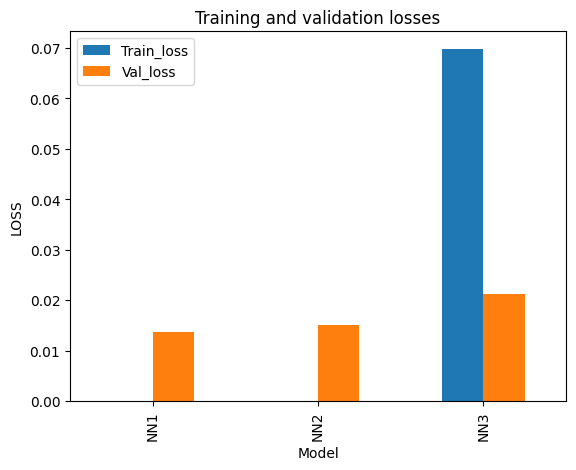

In [165]:
models_comparison = pd.DataFrame({'Model': ['NN1', 'NN2', 'NN3'],
                                 'Train_loss' :[final_train_loss,final_train_loss_2,final_train_loss_3 ],
                                 'Train_acc' : [final_train_accuracy,final_train_accuracy_2,final_train_accuracy_3 ],
                                 'Val_loss' : [final_val_loss,final_val_loss_2,final_val_loss_3 ],
                                  'Val_acc' : [final_val_accuracy,final_val_accuracy_2,final_val_accuracy_3 ]
                                 })

models_comparison[['Model', 'Train_loss', 'Val_loss']].plot(kind = 'bar', x = 'Model')
plt.ylabel("LOSS")
plt.title("Training and validation losses")
plt.show()

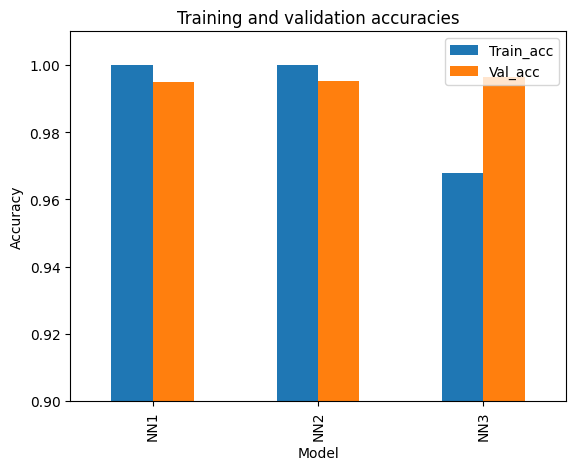

In [166]:
models_comparison[['Model', 'Train_acc', 'Val_acc']].plot(kind = 'bar', x = 'Model')
plt.ylabel("Accuracy")
plt.title("Training and validation accuracies")
plt.ylim((0.9,1.01))
plt.show()

##Testing from external sources:
Fake news from theonion.com: source: https://www.theonion.com/man-feels-like-bystanders-are-arguing-for-him-to-put-gu-1850904549

Real news from BBC: source: https://www.bbc.co.uk/news/business-67056069

I will take a snippet from both via copy and paste

In [167]:
bbc_snippet = """The UK faces another five years of high interest rates to stem rising prices, an influential global group has warned.
The International Monetary Fund expects the UK to have the highest inflation and slowest growth next year of any G7 economy including the US, France, Germany, Canada, Italy and Japan.
However, the Treasury said recent revisions to UK growth had not been factored in to the IMF's report.
The outlook was drawn up before this weekend's developments in Israel.
Forecasts are never perfect given the many factors that affect economic growth - from geopolitics to the weather. But such reports can point in the right direction, especially where they align with other forecasts.
The IMF, an international organisation with 190 member countries, has said the forecasts it makes for growth the following year in most advanced economies have, more often than not, been within about 1.5 percentage points of what actually happens.
In July last year, it forecast that the UK economy would grow by 3.2% in 2022. It revised that upwards to 4.1% at the start of this year.
But official UK figures released last month estimated that the country's economy actually expanded by 4.3% in 2022.
According to the IMF's latest forecast which it produces every six months, it expects the UK to grow more quickly than Germany in 2023, keeping the UK out of bottom place for growth among the G7.
But it downgraded the UK's prospects for growth next year, estimating the economy will grow by 0.6%, making it the slowest growing developed country in 2024 - widely predicted to be a general election year."""

In [168]:
theonion_snippet = """Claiming they had already made up their minds, area man Karl Wooley told reporters Tuesday that he felt like the bystanders who were urging him to put his gun down were arguing in bad faith. “If I’m being honest, it sort of feels like these onlookers are only thinking of themselves when they tell me to drop my pistol,” said Wooley, who observed that no one had even asked him to explain his reasoning for shouting at the top of his lungs and waving around a semiautomatic firearm. “Truth be told, they poisoned the well the second they tried to tackle me and forcibly rip the gun from my hands. But the worst part is how condescending they are—saying things like, ‘Hey, buddy, you don’t really want to do this.’ Maybe if they’d bothered to find out where I’m coming from and what my thoughts on the matter are, they’d know this is exactly what I want to be doing.” At press time, Wooley was reportedly shaking his head at how disrespectful his victims had become when they began resorting to ad hominem attacks like “You’re a monster” as he shot them to death."""
print("Length of BBC snippet",len(bbc_snippet.split()))
print("Length of theonion snippet", len(theonion_snippet.split()))

Length of BBC snippet 269
Length of theonion snippet 194


##Preprocessing: cleaning

In [171]:
import spacy

# Load spaCy English tokenizer
nlp = spacy.load("en_core_web_sm")

def optimized_preprocess(texts):
    result = []
    for text in texts:
        tokens = [token.text.lower() for token in nlp(text) if token.text.isalpha() and token.text.lower() not in stop_words_set]
        result.append(" ".join(tokens))
    return result

# Example usage
bbc_cleaned = optimized_preprocess([bbc_snippet])
theonion_cleaned = optimized_preprocess([theonion_snippet])


In [172]:
## Check
print(bbc_cleaned)
print('\n \n ======================================================== \n \n')
print(theonion_cleaned)

print('\n \n ======================================================== \n \n')

print('BBC length after cleaning: ',len(bbc_cleaned[0].split()))
print('\n \n ======================================================== \n \n')
print('theonion length after cleaning: ',len(theonion_cleaned[0].split()))

['uk faces another five years high interest rates stem rising prices influential global group warned international monetary fund expects uk highest inflation slowest growth next year economy including us france germany canada italy japan however treasury said recent revisions uk growth factored imf report outlook drawn weekend developments israel forecasts never perfect given many factors affect economic growth geopolitics weather reports point right direction especially align forecasts imf international organisation member countries said forecasts makes growth following year advanced economies often within percentage points actually happens july last year forecast uk economy would grow revised upwards start year official uk figures released last month estimated country economy actually expanded according imf latest forecast produces every six months expects uk grow quickly germany keeping uk bottom place growth among downgraded uk prospects growth next year estimating economy grow mak

##Preprocessing: sequencing and padding
Sequencing

In [173]:
bbc_seq = tokenizer.texts_to_sequences(bbc_cleaned)
theonion_seq = tokenizer.texts_to_sequences(theonion_cleaned)

## Check
print(bbc_seq[0]);print(len(bbc_seq[0]))
print(theonion_seq)

[1272, 1477, 108, 370, 38, 199, 667, 1728, 5686, 2061, 1866, 3300, 471, 74, 891, 195, 4237, 753, 3186, 1272, 1448, 4710, 1, 1099, 132, 19, 458, 78, 37, 874, 523, 1177, 1837, 843, 203, 1305, 3, 250, 1, 1272, 1099, 1, 1, 150, 6812, 2410, 1152, 5363, 426, 1, 140, 2044, 355, 41, 4977, 2421, 273, 1099, 1, 4012, 330, 282, 53, 2332, 666, 9761, 1, 1, 195, 6311, 261, 170, 3, 1, 528, 1099, 317, 19, 3152, 4698, 623, 447, 2156, 763, 280, 1660, 321, 30, 19, 5327, 1272, 458, 5, 2788, 4722, 1, 529, 19, 131, 1272, 1899, 341, 30, 157, 1772, 34, 458, 280, 2966, 64, 1, 515, 5327, 9856, 165, 489, 215, 3186, 1272, 2788, 980, 523, 1589, 1272, 2516, 207, 1099, 228, 1, 1272, 4527, 1099, 132, 19, 1, 458, 2788, 251, 1, 1042, 3256, 34, 1793, 3669, 126, 26, 19]
147
[[1475, 202, 50, 3748, 646, 138, 8499, 1, 22, 276, 100, 1433, 24, 1, 2699, 178, 275, 2846, 510, 1881, 2723, 1644, 2801, 24, 1, 1544, 509, 1612, 1, 3, 1, 5551, 7, 36, 120, 1495, 7147, 4661, 156, 1, 6227, 144, 1, 4822, 707, 22, 6996, 85, 328, 604, 4064, 

Padding

In [174]:
bbc_pad = pad_sequences(bbc_seq, maxlen= avg_length_text, padding = 'post', truncating = 'post')
theonion_pad = pad_sequences(theonion_seq, maxlen=  avg_length_text, padding = 'post', truncating = 'post')

In [175]:
## Check
print(bbc_pad.shape)
print(bbc_pad[0].shape)
print(len(bbc_pad[0]))  ## the first in the list is the padded sequence

(1, 236)
(236,)
236


##Testing the models on real (BBC) and fake (The Onion)


In [176]:
print(bbc_pad.shape)
print(model.summary())

(1, 236)
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding (Embedding)       (None, 236, 16)           1681280   
                                                                 
 flatten (Flatten)           (None, 3776)              0         
                                                                 
 dense (Dense)               (None, 16)                60432     
                                                                 
 batch_normalization (Batch  (None, 16)                64        
 Normalization)                                                  
                                                                 
 dense_1 (Dense)             (None, 1)                 17        
                                                                 
Total params: 1741793 (6.64 MB)
Trainable params: 1741761 (6.64 MB)
Non-trainable params: 32 (128.00 Byte)
______

In [177]:
print(model.predict(bbc_pad))
print(model.predict(theonion_pad))

print('\n\n ======================= \n\n')

print(model_2.predict(bbc_pad))
print(model_2.predict(theonion_pad))

print('\n\n ======================= \n\n')

print(model_3.predict(bbc_pad))
print(model_3.predict(theonion_pad))

print('\n\n ======================= \n\n')

1/1 [==============================] - 0s 192ms/step
[[0.85823953]]
1/1 [==============================] - 0s 36ms/step
[[1.8801418e-05]]




1/1 [==============================] - 0s 98ms/step
[[0.49788386]]
1/1 [==============================] - 0s 34ms/step
[[0.4888618]]




1/1 [==============================] - 0s 102ms/step
[[0.85721433]]
1/1 [==============================] - 0s 36ms/step
[[2.5847112e-05]]






##Results: MODEL 3 CLEARLY WINS
In this case, model 1 and 2 fail to convincingly separate out both test observations, despite one clearly being a false article. Specifically, model 1 predicted both to be true articles (with the output of the model being very close to 0), while model 2 was on the fence, predicting both to be around the 50% threshold, not being able to confidently choose either side.

This is where model 3 clearly excelled, having predicted 0.1 probability that the BBC article was false, and 0.87 for The Onion, displaying a large confidence in the correct answers.

In [178]:
## recap on the models

print(model.summary())
print("\n\n=================================================================================================== \n\n")
print(model_2.summary())
print("\n\n=================================================================================================== \n\n")
print(model_3.summary())

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding (Embedding)       (None, 236, 16)           1681280   
                                                                 
 flatten (Flatten)           (None, 3776)              0         
                                                                 
 dense (Dense)               (None, 16)                60432     
                                                                 
 batch_normalization (Batch  (None, 16)                64        
 Normalization)                                                  
                                                                 
 dense_1 (Dense)             (None, 1)                 17        
                                                                 
Total params: 1741793 (6.64 MB)
Trainable params: 1741761 (6.64 MB)
Non-trainable params: 32 (128.00 Byte)
_______________

##Moving onto sequential models (RNNs, LSTMs)
So far, we have been dealing with models that treat predictors (words) independently and have not been able to incorporate any sequentiality which is obviously critical in speech and text. Words in a sentence have a particular order that otherwise would not make sense to another human being. So far, we have been using models that could hopefully detect words that are commonly used in real vs fake articles, instead of properly understanding the text which could lead to better results.

Furthermore, sequantial models can allow for articles of varying length. RNNs and LSTMs handle them more naturally.
In this case, we are doing a special form of prediction that is 'many to one', where we take a sequence of words but only produce a single output, but where the decision is only made at the last word.

##Model 2.1: basic RNN
We will use a basic recurrent layer. There are some limitations, such as exploding/vanishing gradients due to the 'recurrent' nature and may struggle with long term dependencies, as our documents have varying lengths and a large proportion of them are high in lengths.

As StatQuest explains, they are thought of as a 'stepping tone to understanding fancier things like LTSMs and Transformers...'

For recurrent neural network, the intermediate 'predictions' are not used as final predictions, but rather as intermediate inputs to inform on the next prediction, which itself is also used as the new intermediate input. They thus serve as accumulated representation of the sequence up till that point.

In [179]:
len(word_index)

105080

It is common to add a Dense layer right before the final layer when working with RNNs



In [180]:
from tensorflow.keras.layers import SimpleRNN

model_rnn = Sequential([
    Embedding(input_dim = len(word_index), output_dim = 8,
             input_length=avg_length_text), ## recall that we set the post-padding length to be this value
    SimpleRNN(16), ## THIS IS THE RECURRENT LAYER
    Dropout(0.2),
    Dense(8, activation='relu'),
    Dropout(0.2),
    Dense(1, activation= 'sigmoid') ## final layer for prediction, hence only one node
])

## compile -- add optim, add loss, add metrics
model_rnn.compile(optimizer = 'adam', loss = ['binary_crossentropy'], metrics = ['accuracy'])

early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history_rnn = model_rnn.fit(X_train_pad, y_train, epochs=10, batch_size=200, validation_data=(X_test_pad, y_test), callbacks=[early_stopping])

Epoch 1/10
180/180 [==============================] - 16s 79ms/step - loss: 0.4089 - accuracy: 0.8329 - val_loss: 0.1300 - val_accuracy: 0.9705
Epoch 2/10
180/180 [==============================] - 14s 77ms/step - loss: 0.1155 - accuracy: 0.9756 - val_loss: 0.0836 - val_accuracy: 0.9792
Epoch 3/10
180/180 [==============================] - 14s 77ms/step - loss: 0.0734 - accuracy: 0.9848 - val_loss: 0.0763 - val_accuracy: 0.9798
Epoch 4/10
180/180 [==============================] - 14s 78ms/step - loss: 0.0510 - accuracy: 0.9898 - val_loss: 0.0910 - val_accuracy: 0.9781
Epoch 5/10
180/180 [==============================] - 14s 77ms/step - loss: 0.0401 - accuracy: 0.9916 - val_loss: 0.1752 - val_accuracy: 0.9559
Epoch 6/10
180/180 [==============================] - 14s 77ms/step - loss: 0.0445 - accuracy: 0.9903 - val_loss: 0.1150 - val_accuracy: 0.9724
Epoch 7/10
180/180 [==============================] - 14s 80ms/step - loss: 0.0315 - accuracy: 0.9932 - val_loss: 0.1135 - val_accuracy:

##Evaluate Model 1.3


In [181]:
final_train_loss_4 = history_rnn.history['loss'][-1]
final_train_accuracy_4 = history_rnn.history['accuracy'][-1]

final_val_loss_4 = history_rnn.history['val_loss'][-1]
final_val_accuracy_4 = history_rnn.history['val_accuracy'][-1]

print("Final Training Loss:", final_train_loss_4)
print("Final Training Accuracy:", final_train_accuracy_4)
print("Final Validation Loss:", final_val_loss_4)
print("Final Validation Accuracy:", final_val_accuracy_4)

Final Training Loss: 0.4171917140483856
Final Training Accuracy: 0.8987137079238892
Final Validation Loss: 0.10360436886548996
Final Validation Accuracy: 0.9708240628242493


In [182]:
models_comparison.loc[len(models_comparison)] =  ['RNN1', final_train_loss_4, final_train_accuracy_4, final_val_loss_4, final_val_accuracy_4]

In [183]:
## Show models comparison
models_comparison

,Model,Train_loss,Train_acc,Val_loss,Val_acc
0,NN1,0.000036,1.000000,0.013745,0.994989
1,NN2,0.000009,1.000000,0.015116,0.995212
2,NN3,0.069734,0.968010,0.021168,0.996437
3,RNN1,0.417192,0.898714,0.103604,0.970824


##Result: RNNs massively underperforms the prior networks, but bear in mind we had only trained it for 10 epochs

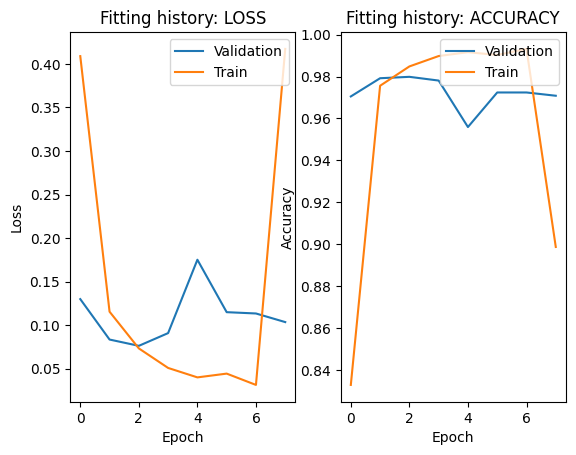

In [184]:
plt.subplot(1,2,1)
plt.plot(history_rnn.history['val_loss']) ## validation loss
plt.plot(history_rnn.history['loss']) ## training loss (should be decreasing)
plt.title("Fitting history: LOSS")
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Validation', 'Train'], loc = 'upper right')

plt.subplot(1,2,2)
plt.plot(history_rnn.history['val_accuracy']) ## validation loss
plt.plot(history_rnn.history['accuracy']) ## training loss (should be decreasing)
plt.title("Fitting history: ACCURACY")
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Validation', 'Train'], loc = 'upper right')


plt.show()

Here it is clear that for training this RNN, the losses and accuracies do not change as steadily over time (epochs) as in the previous cases, but this may also be unfair due to the small sample and short training time (only 10 epochs)

##Predicting on external sources (BBC and The Onion)

In [185]:
print(model_rnn.predict(bbc_pad))
print(model_rnn.predict(theonion_pad))

1/1 [==============================] - 0s 276ms/step
[[0.9923279]]
1/1 [==============================] - 0s 44ms/step
[[0.01230863]]


Poor results on external sources as well.
##Model 2.2: Try training for longer!
By reusing the same model and fitting it, we are carrying on where we last left off when training the model_rnn model, and hence not starting from scratch. This helps us do additional training.

In [186]:
history_rnn_2 = model_rnn.fit(X_train_pad, y_train, epochs=40, batch_size=200, validation_data=(X_test_pad, y_test), callbacks=[early_stopping])

Epoch 1/40
180/180 [==============================] - 16s 90ms/step - loss: 0.0428 - accuracy: 0.9922 - val_loss: 0.0808 - val_accuracy: 0.9791
Epoch 2/40
180/180 [==============================] - 21s 118ms/step - loss: 0.0308 - accuracy: 0.9952 - val_loss: 0.0842 - val_accuracy: 0.9781
Epoch 3/40
180/180 [==============================] - 14s 78ms/step - loss: 0.0218 - accuracy: 0.9969 - val_loss: 0.0882 - val_accuracy: 0.9778
Epoch 4/40
180/180 [==============================] - 14s 77ms/step - loss: 0.0184 - accuracy: 0.9975 - val_loss: 0.0957 - val_accuracy: 0.9773
Epoch 5/40
180/180 [==============================] - 14s 77ms/step - loss: 0.0180 - accuracy: 0.9976 - val_loss: 0.0947 - val_accuracy: 0.9790
Epoch 6/40
180/180 [==============================] - 14s 77ms/step - loss: 0.0192 - accuracy: 0.9967 - val_loss: 0.1040 - val_accuracy: 0.9772


In [187]:
print('The model trained for ' ,len(history_rnn_2.history['loss']), ' more epochs before stopping presumably due to early stopping')

The model trained for  6  more epochs before stopping presumably due to early stopping


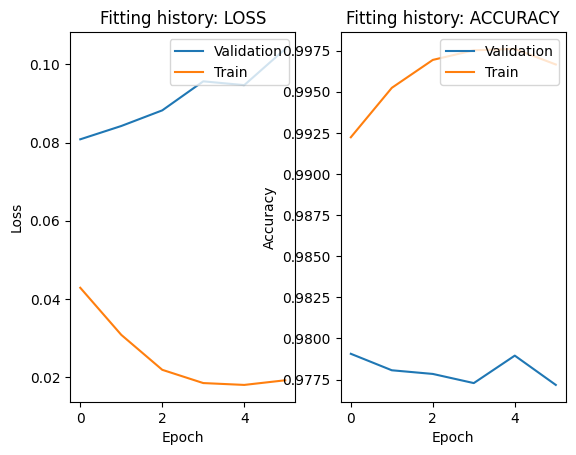

In [188]:
plt.subplot(1,2,1)
plt.plot(history_rnn_2.history['val_loss']) ## validation loss
plt.plot(history_rnn_2.history['loss']) ## training loss (should be decreasing)
plt.title("Fitting history: LOSS")
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Validation', 'Train'], loc = 'upper right')

plt.subplot(1,2,2)
plt.plot(history_rnn_2.history['val_accuracy']) ## validation loss
plt.plot(history_rnn_2.history['accuracy']) ## training loss (should be decreasing)
plt.title("Fitting history: ACCURACY")
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Validation', 'Train'], loc = 'upper right')


plt.show()

There is a bit more stability here - we can at least see that the training loss is decreasing, and both training and validation accuracies are increasing here.

In [189]:
final_train_loss_5 = history_rnn_2.history['loss'][-1]
final_train_accuracy_5 = history_rnn_2.history['accuracy'][-1]

final_val_loss_5 = history_rnn_2.history['val_loss'][-1]
final_val_accuracy_5 = history_rnn_2.history['val_accuracy'][-1]

print("Final Training Loss:", final_train_loss_5)
print("Final Training Accuracy:", final_train_accuracy_5)
print("Final Validation Loss:", final_val_loss_5)
print("Final Validation Accuracy:", final_val_accuracy_5)

Final Training Loss: 0.019151998683810234
Final Training Accuracy: 0.9966590404510498
Final Validation Loss: 0.10395875573158264
Final Validation Accuracy: 0.9771714806556702


In [190]:
models_comparison.loc[len(models_comparison)] =  ['RNN2_more_epochs', final_train_loss_5, final_train_accuracy_5, final_val_loss_5, final_val_accuracy_5]
models_comparison

,Model,Train_loss,Train_acc,Val_loss,Val_acc
0,NN1,0.000036,1.000000,0.013745,0.994989
1,NN2,0.000009,1.000000,0.015116,0.995212
2,NN3,0.069734,0.968010,0.021168,0.996437
3,RNN1,0.417192,0.898714,0.103604,0.970824
4,RNN2_more_epochs,0.019152,0.996659,0.103959,0.977171


Although training numbers have improved, the validation numbers seemed to have worsened. This could potentially be a indication of overfitting

In [191]:
print(model_rnn.predict(bbc_pad))
print(model_rnn.predict(theonion_pad))

1/1 [==============================] - 0s 69ms/step
[[0.0025771]]
1/1 [==============================] - 0s 92ms/step
[[0.02447426]]


However, the results on the external sources is much better now and close to the neural network model_3 in terms of predictive power on the test observations.

##Model 3: LSTM layers
LSTM layers help to solve the vanishing/exploding gradient problem by allowing there to be a long term memory that will not be implicated as much by backpropagation. LSTMs also have gates that control the amount of information and information that go into both the long term memory and the short term memory. Compared to RNNs, this helps with better long term memory.

In [192]:
from tensorflow.keras.layers import LSTM

model_lstm = Sequential([
    Embedding(input_dim=len(word_index) + 1, output_dim=8, input_length=avg_length_text),
    LSTM(16),  # 16 LSTM units
    Dropout(0.2),
    Dense(8, activation='relu'),
    Dropout(0.2),  # Adding dropout
    Dense(1, activation='sigmoid')
])

model_lstm.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history_lstm = model_lstm.fit(X_train_pad, y_train, epochs=50, batch_size=200,
                              validation_data=(X_test_pad, y_test), callbacks=[early_stopping])

Epoch 1/50
180/180 [==============================] - 32s 142ms/step - loss: 0.5331 - accuracy: 0.7560 - val_loss: 0.3542 - val_accuracy: 0.8830
Epoch 2/50
180/180 [==============================] - 26s 145ms/step - loss: 0.3475 - accuracy: 0.9008 - val_loss: 0.2923 - val_accuracy: 0.9076
Epoch 3/50
180/180 [==============================] - 40s 221ms/step - loss: 0.2887 - accuracy: 0.9151 - val_loss: 0.1796 - val_accuracy: 0.9552
Epoch 4/50
180/180 [==============================] - 29s 162ms/step - loss: 0.1544 - accuracy: 0.9674 - val_loss: 0.1419 - val_accuracy: 0.9699
Epoch 5/50
180/180 [==============================] - 27s 148ms/step - loss: 0.1549 - accuracy: 0.9693 - val_loss: 0.1196 - val_accuracy: 0.9719
Epoch 6/50
180/180 [==============================] - 26s 144ms/step - loss: 0.1186 - accuracy: 0.9773 - val_loss: 0.1441 - val_accuracy: 0.9625
Epoch 7/50
180/180 [==============================] - 26s 147ms/step - loss: 0.1182 - accuracy: 0.9771 - val_loss: 0.1358 - val_ac

In [193]:
print("Number of epochs to train ", len(history_lstm.history['loss']))

Number of epochs to train  19


In [194]:
final_train_loss_6 = history_lstm.history['loss'][-1]
final_train_accuracy_6 = history_lstm.history['accuracy'][-1]

final_val_loss_6 = history_lstm.history['val_loss'][-1]
final_val_accuracy_6 = history_lstm.history['val_accuracy'][-1]

print("Final Training Loss:", final_train_loss_6)
print("Final Training Accuracy:", final_train_accuracy_6)
print("Final Validation Loss:", final_val_loss_6)
print("Final Validation Accuracy:", final_val_accuracy_6)

Final Training Loss: 0.2465948611497879
Final Training Accuracy: 0.9183139204978943
Final Validation Loss: 0.22375331819057465
Final Validation Accuracy: 0.923496663570404


In [195]:
print(model_lstm.predict(bbc_pad))
print(model_lstm.predict(theonion_pad))

1/1 [==============================] - 0s 450ms/step
[[0.9950612]]
1/1 [==============================] - 0s 29ms/step
[[0.02408038]]


The predictions for both test instances are oddly close. Let us take a look at the predictions from the validation cases

In [196]:
model_lstm.predict(X_test_pad)

281/281 [==============================] - 6s 20ms/step


array([[0.99378157],
       [0.02399057],
       [0.05165167],
       ...,
       [0.91241163],
       [0.9950585 ],
       [0.03054008]], dtype=float32)